# PhisGuard: URL Threat Detection Engine
Notebook Eksperimen dan Pipeline Deteksi URL Phishing

---

### Informasi Proyek dan Roadmap Model
* Domain: Cybersecurity / Phishing URL Detection
* Target Model (Production): XGBoost Classifier
* Baseline Model: Random Forest Classifier
* Nama Dataset: LegitPhish Dataset
* Sumber Dataset: Mendeley Data (DOI: [10.17632/hx4m73v2sf.2](https://data.mendeley.com/datasets/hx4m73v2sf/2))
* Penulis: Rachana Potpelwar, Uday Kulkarni, Jaishri Waghmare (2025)
* Sumber Koleksi:
  * Phishing URLs: URLHaus dan PhishTank (feed intelijen ancaman terverifikasi)
  * Legitimate URLs: Google Search API, Wikipedia, dan Stack Overflow

---
### Struktur Notebook
1. CHAPTER 1 : Dataset Quality Audit
2. CHAPTER 2 : Data Cleaning & Preprocessing
3. CHAPTER 3 : Model Training & Evaluation (Tahap Selanjutnya)


# CHAPTER 1 : Dataset Quality Audit

Bab ini berfokus pada audit komprehensif kualitas data mentah LegitPhish:
1. Integritas skema, tipe data, missing values, dan nilai sentinel.
2. Identifikasi artefak data kotor dan duplikasi baris.
3. Distribusi kelas dan verifikasi polaritas label target.
4. Profiling statistik tendensi sentral (Mean vs Median), IQR, dan skewness.
5. Uji hipotesis statistik (Mann-Whitney U Test) dan peringkat Effect Size (Cohen's d).
6. Analisis multikolinearitas dan korelasi antar fitur.
7. Evaluasi risiko bias sumber data (HTTPS flag dan domain authority).


## 1.1 Problem Framing & Decision Canvas (/data-question-framing)

* Unit of Analysis: Satu baris URL tunggal beserta 16 fitur leksikal numerik yang diekstrak.
* Target Definition: Kolom ClassLabel.
  * Catatan Polarisasi Label Mentah: Pada dataset LegitPhish, nilai 0.0 mewakili Phishing dan 1.0 mewakili Legitimate.
* Baseline vs Candidate Model:
  * Baseline: Random Forest Classifier.
  * Kandidat Produksi: XGBoost Classifier.
* Guardrail Metric: False Positive Rate (FPR) pada URL legitimate harus ditekan seminimal mungkin agar tidak mengganggu akses pengguna ke situs sah, sementara Recall pada kelas Phishing harus dioptimalkan.


## 1.2 Data Ingestion & Structural Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set visual styling tanpa emotikon
sns.set_theme(style='whitegrid', font='sans-serif')
palette = {'Phishing (0)': '#e74c3c', 'Legitimate (1)': '#2ecc71'}

DATA_PATH = Path('../data/url/url_features_extracted1.csv')
PLOT_DIR = Path('../plots/url')
PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(DATA_PATH)
print("Dataset URL mentah berhasil dimuat.")
print(f"Dimensi Data: {df_raw.shape[0]:,} baris, {df_raw.shape[1]} kolom.")
df_raw.head(3)


Dataset URL mentah berhasil dimuat.
Dimensi Data: 101,219 baris, 18 kolom.


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0


## 1.3 Schema & Data Type Verification

In [2]:
schema_info = pd.DataFrame({
    'Column': df_raw.columns,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Null Count': df_raw.isnull().sum().values,
    'Dtype': df_raw.dtypes.values
})
print("Ringkasan Skema Kolom:")
display(schema_info)

mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Estimasi Penggunaan Memori: {mem_mb:.2f} MB")


Ringkasan Skema Kolom:


,Column,Non-Null Count,Null Count,Dtype
0,URL,101219,0,str
1,url_length,101219,0,int64
2,has_ip_address,101219,0,int64
3,dot_count,101219,0,int64
4,https_flag,101219,0,int64
5,url_entropy,101219,0,float64
6,token_count,101219,0,int64
7,subdomain_count,101219,0,int64
8,query_param_count,101219,0,int64
9,tld_length,101219,0,int64


Estimasi Penggunaan Memori: 17.28 MB


## 1.4 Missing Values & Data Corruption Anomaly Audit

Pemeriksaan keberadaan missing value (NaN), nilai sentinel, dan artefak crawler.


In [3]:
null_series = df_raw.isnull().sum()
null_cols = null_series[null_series > 0]
print("Audit Missing Values:")
if len(null_cols) == 0:
    print("Tidak ada missing value.")
else:
    for col, val in null_cols.items():
        print(f"- Kolom '{col}': {val} missing value ({val/len(df_raw)*100:.4f}%)")

null_row = df_raw[df_raw['ClassLabel'].isnull()]
print("\nBaris dengan ClassLabel NaN:")
display(null_row[['URL', 'url_length', 'ClassLabel']])

negative_subdomains = (df_raw['subdomain_count'] < 0).sum()
print(f"\nJumlah baris dengan subdomain_count < 0 (nilai sentinel -1): {negative_subdomains:,} baris")

status_artifacts = df_raw[df_raw['URL'].str.lower().isin(['offline', 'online', 'error', '404', 'nan'])]
print(f"Jumlah artefak status crawler pada kolom URL: {len(status_artifacts)}")
display(status_artifacts[['URL', 'url_length', 'subdomain_count', 'ClassLabel']])


Audit Missing Values:
- Kolom 'ClassLabel': 1 missing value (0.0010%)

Baris dengan ClassLabel NaN:


,URL,url_length,ClassLabel
65118,https://www.chocolatleroux.com,30,NaN



Jumlah baris dengan subdomain_count < 0 (nilai sentinel -1): 1,308 baris


Jumlah artefak status crawler pada kolom URL: 1


,URL,url_length,subdomain_count,ClassLabel
599,Offline,7,-1,0.0


## 1.5 Deduplication & Integrity Audit

In [4]:
exact_duplicates = df_raw.duplicated().sum()
print(f"Duplikasi Baris Persis (Identik di semua kolom): {exact_duplicates:,}")

url_duplicates = df_raw['URL'].duplicated().sum()
print(f"Duplikasi pada Kolom URL: {url_duplicates:,}")

url_label_conflict = df_raw.groupby('URL')['ClassLabel'].nunique()
conflicting_urls = url_label_conflict[url_label_conflict > 1]
print(f"Jumlah URL dengan Label Bertentangan: {len(conflicting_urls)}")

# Subset bersih sementara untuk analisis statistik audit
df_audit = df_raw.dropna(subset=['ClassLabel']).copy()
df_audit['ClassLabel'] = df_audit['ClassLabel'].astype(int)
df_audit['Class_Name'] = df_audit['ClassLabel'].map({0: 'Phishing (0)', 1: 'Legitimate (1)'})


Duplikasi Baris Persis (Identik di semua kolom): 346


Duplikasi pada Kolom URL: 346


Jumlah URL dengan Label Bertentangan: 0


## 1.6 Class Distribution & Imbalance Audit

Distribusi Kelas Target:
- Phishing (0): 63,678 sampel (62.91%)
- Legitimate (1): 37,540 sampel (37.09%)
Rasio Ketidakseimbangan (Phishing : Legitimate): 1.70 : 1


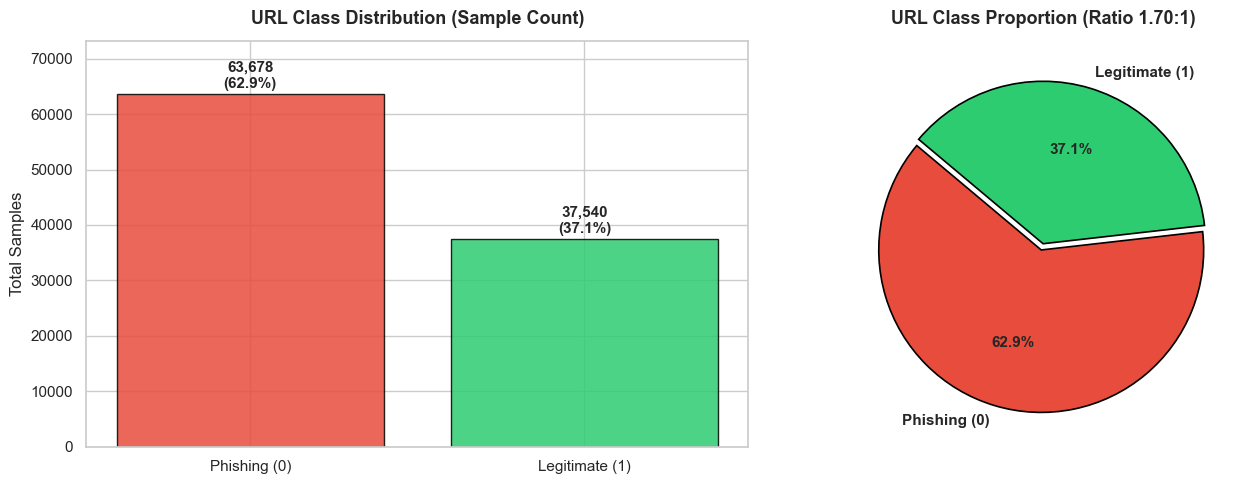

Plot disimpan di: plots\url\01_url_class_distribution.png


In [5]:
class_counts = df_audit['Class_Name'].value_counts()
class_pcts = df_audit['Class_Name'].value_counts(normalize=True) * 100
imbalance_ratio = class_counts['Phishing (0)'] / class_counts['Legitimate (1)']

print("Distribusi Kelas Target:")
for cname in class_counts.index:
    print(f"- {cname}: {class_counts[cname]:,} sampel ({class_pcts[cname]:.2f}%)")
print(f"Rasio Ketidakseimbangan (Phishing : Legitimate): {imbalance_ratio:.2f} : 1")

# Visualisasi Distribusi Kelas
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar(class_counts.index, class_counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', alpha=0.85)
for i, v in enumerate(class_counts.values):
    pct = v / len(df_audit) * 100
    ax[0].text(i, v + 1000, f'{v:,}\n({pct:.1f}%)', ha='center', fontweight='bold', fontsize=11)
ax[0].set_title('URL Class Distribution (Sample Count)', fontsize=13, fontweight='bold', pad=12)
ax[0].set_ylabel('Total Samples')
ax[0].set_ylim(0, max(class_counts.values) * 1.15)

ax[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'],
          startangle=140, explode=(0.04, 0), wedgeprops={'edgecolor': 'black', 'linewidth': 1.2},
          textprops={'fontsize': 11, 'fontweight': 'bold'})
ax[1].set_title(f'URL Class Proportion (Ratio {imbalance_ratio:.2f}:1)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plot_file1 = PLOT_DIR / '01_url_class_distribution.png'
plt.savefig(plot_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {plot_file1}")


## 1.7 Statistical Profiling & Central Tendency (/statistical-analysis)

In [6]:
num_cols = df_audit.select_dtypes(include=[np.number]).columns.drop('ClassLabel').tolist()

stat_summary = []
for col in num_cols:
    s = df_audit[col]
    mean_val = s.mean()
    median_val = s.median()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = s.skew()
    stat_summary.append({
        'Feature': col,
        'Mean': round(mean_val, 2),
        'Median': round(median_val, 2),
        'Std': round(s.std(), 2),
        'IQR': round(iqr_val, 2),
        'Skewness': round(skew_val, 2),
        'Min': round(s.min(), 2),
        'p1': round(s.quantile(0.01), 2),
        'p25': round(s.quantile(0.25), 2),
        'p50': round(median_val, 2),
        'p75': round(s.quantile(0.75), 2),
        'p99': round(s.quantile(0.99), 2),
        'Max': round(s.max(), 2)
    })

stat_df = pd.DataFrame(stat_summary)
print("Ringkasan Statistik 16 Fitur Numerik:")
display(stat_df)


Ringkasan Statistik 16 Fitur Numerik:


,Feature,Mean,Median,Std,IQR,Skewness,Min,p1,p25,p50,p75,p99,Max
0,url_length,35.06,31.00,16.81,8.00,5.83,7.00,19.00,27.00,31.00,35.00,87.83,474.00
1,has_ip_address,0.48,0.00,0.50,1.00,0.06,0.00,0.00,0.00,0.00,1.00,1.00,1.00
2,dot_count,3.01,3.00,0.95,2.00,1.40,0.00,2.00,2.00,3.00,4.00,5.00,19.00
3,https_flag,0.41,0.00,0.49,1.00,0.38,0.00,0.00,0.00,0.00,1.00,1.00,1.00
4,url_entropy,3.98,3.94,0.31,0.33,0.86,2.52,3.42,3.77,3.94,4.10,4.80,5.87
5,token_count,6.89,7.00,1.67,3.00,2.24,1.00,5.00,5.00,7.00,8.00,11.00,48.00
6,subdomain_count,1.51,2.00,0.62,1.00,-1.04,-1.00,-1.00,1.00,2.00,2.00,2.00,5.00
7,query_param_count,1.01,1.00,0.20,0.00,33.43,1.00,1.00,1.00,1.00,1.00,1.00,14.00
8,tld_length,5.00,3.00,2.92,5.00,0.34,0.00,0.00,3.00,3.00,8.00,9.00,10.00
9,path_length,8.54,2.00,14.70,7.00,4.77,0.00,0.00,0.00,2.00,7.00,60.00,317.00


## 1.8 Bivariate Hypothesis Testing & Feature Discriminative Power

Hasil Uji Hipotesis Mann-Whitney U dan Effect Size Cohen's d:


,Feature,Phish_Mean,Phish_Median,Legit_Mean,Legit_Median,Cohen_d,p_value
3,https_flag,0.055,0.000,1.000,1.00,-5.205,0.000000e+00
15,percentage_numeric_chars,38.220,45.455,0.248,0.00,2.918,0.000000e+00
5,token_count,7.882,8.000,5.196,5.00,2.555,0.000000e+00
11,number_of_digits,13.477,15.000,0.081,0.00,2.403,0.000000e+00
1,has_ip_address,0.771,1.000,0.000,0.00,2.312,0.000000e+00
2,dot_count,3.510,4.000,2.155,2.00,1.981,0.000000e+00
8,tld_length,6.345,8.000,2.727,3.00,1.549,0.000000e+00
12,tld_popularity,0.115,0.000,0.691,1.00,-1.523,0.000000e+00
14,domain_name_length,4.114,3.000,9.986,10.00,-1.297,0.000000e+00
6,subdomain_count,1.722,2.000,1.155,1.00,1.009,0.000000e+00


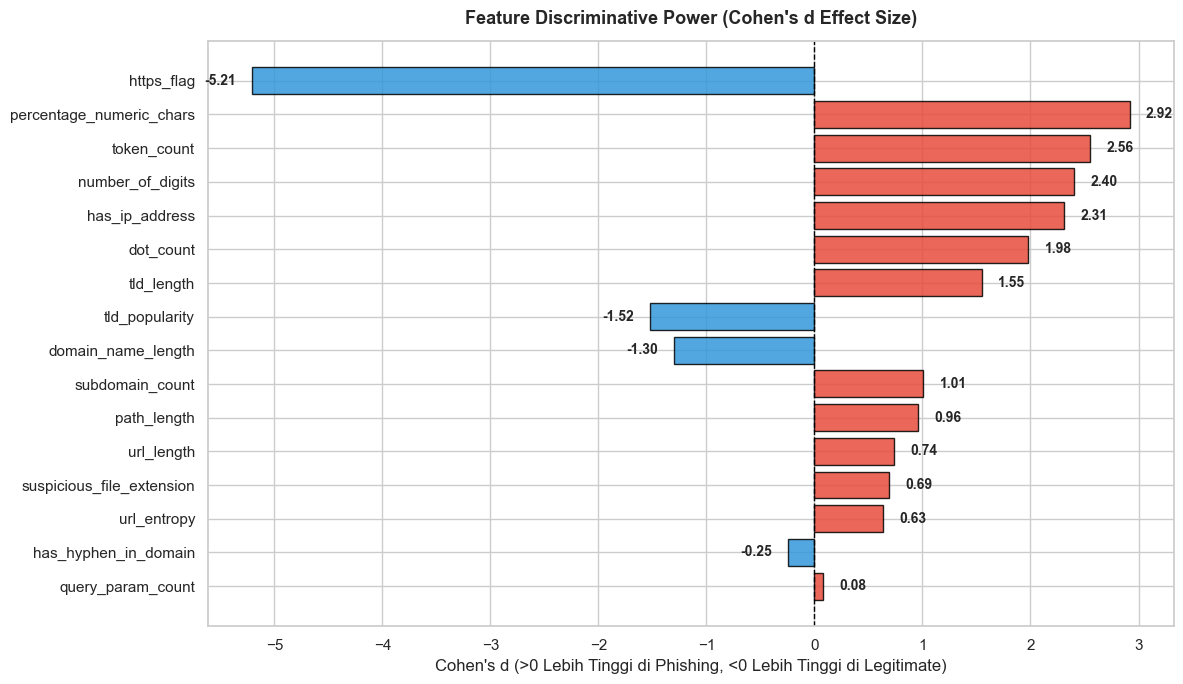

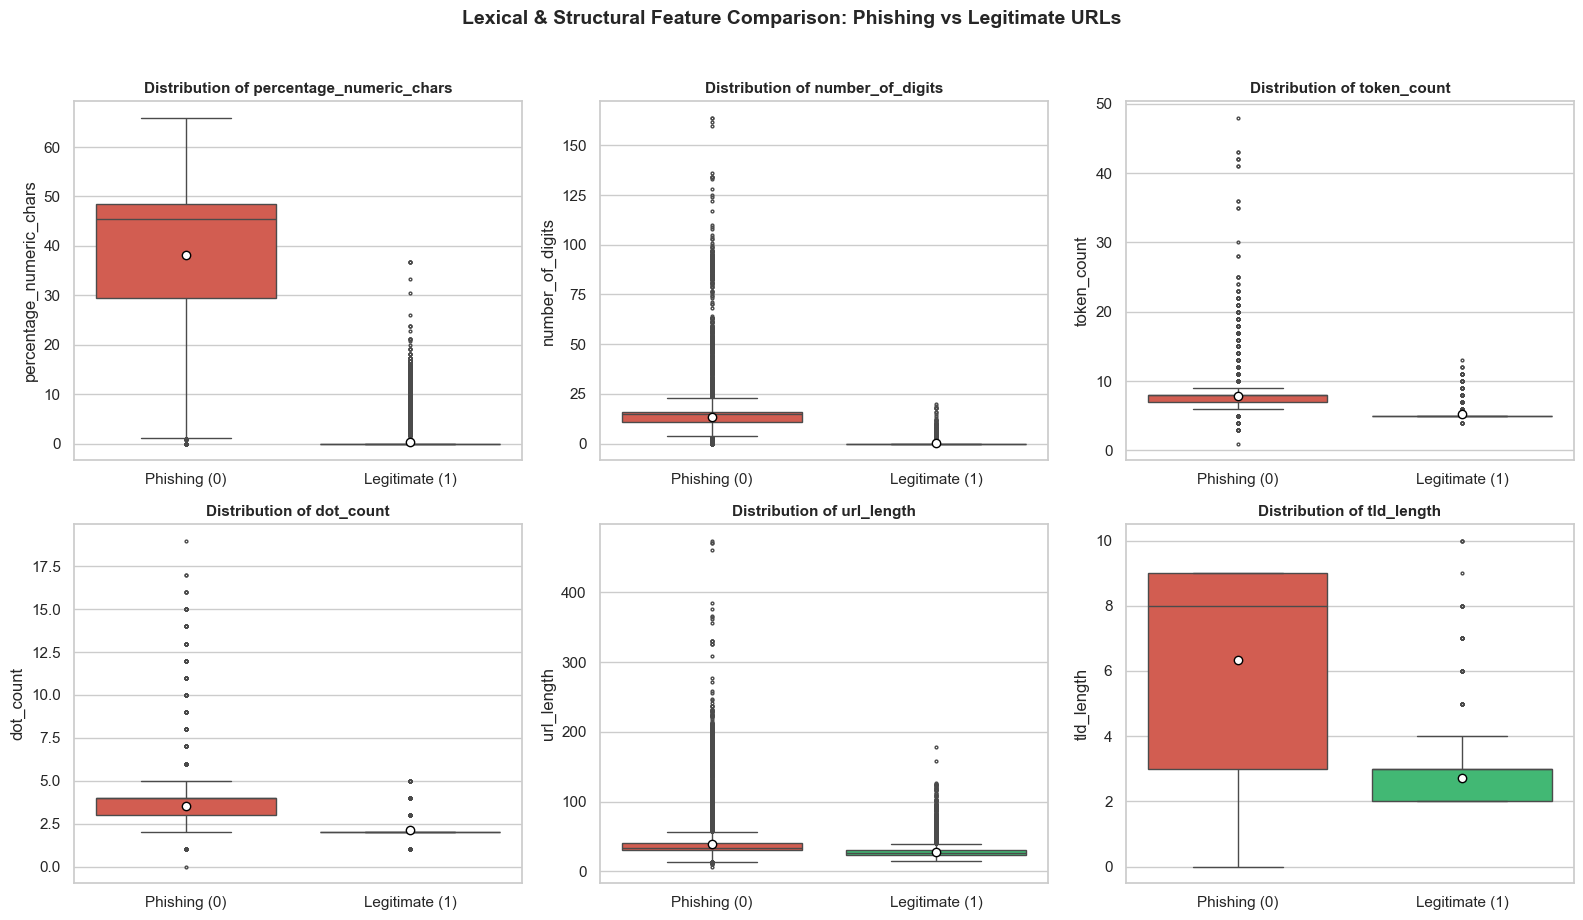

In [7]:
phish_data = df_audit[df_audit['ClassLabel'] == 0]
legit_data = df_audit[df_audit['ClassLabel'] == 1]

tests = []
for col in num_cols:
    p_s = phish_data[col]
    l_s = legit_data[col]
    
    u_stat, p_val = stats.mannwhitneyu(p_s, l_s, alternative='two-sided')
    
    n1, n2 = len(p_s), len(l_s)
    s1, s2 = p_s.std(), l_s.std()
    pooled_s = np.sqrt(((n1 - 1)*(s1**2) + (n2 - 1)*(s2**2)) / (n1 + n2 - 2))
    cohen_d = (p_s.mean() - l_s.mean()) / (pooled_s + 1e-9)
    
    tests.append({
        'Feature': col,
        'Phish_Mean': round(p_s.mean(), 3),
        'Phish_Median': round(p_s.median(), 3),
        'Legit_Mean': round(l_s.mean(), 3),
        'Legit_Median': round(l_s.median(), 3),
        'Cohen_d': round(cohen_d, 3),
        'Abs_Cohen_d': round(abs(cohen_d), 3),
        'p_value': p_val
    })

hypo_df = pd.DataFrame(tests).sort_values(by='Abs_Cohen_d', ascending=False)
print("Hasil Uji Hipotesis Mann-Whitney U dan Effect Size Cohen's d:")
display(hypo_df[['Feature', 'Phish_Mean', 'Phish_Median', 'Legit_Mean', 'Legit_Median', 'Cohen_d', 'p_value']])

# Visualisasi Ranking Cohen's d
plt.figure(figsize=(12, 7))
eff_sorted = hypo_df.sort_values(by='Abs_Cohen_d', ascending=True)
bar_colors = ['#e74c3c' if x > 0 else '#3498db' for x in eff_sorted['Cohen_d']]
bars = plt.barh(eff_sorted['Feature'], eff_sorted['Cohen_d'], color=bar_colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title("Feature Discriminative Power (Cohen's d Effect Size)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cohen's d (>0 Lebih Tinggi di Phishing, <0 Lebih Tinggi di Legitimate)")
for bar in bars:
    w = bar.get_width()
    ha = 'left' if w > 0 else 'right'
    offset = 0.15 if w > 0 else -0.15
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:.2f}', va='center', ha=ha, fontsize=10, fontweight='bold')
plt.tight_layout()
plot_file4 = PLOT_DIR / '04_url_effect_size_ranking.png'
plt.savefig(plot_file4, dpi=200, bbox_inches='tight')
plt.show()

# Boxplot Fitur Kunci
top_cols = ['percentage_numeric_chars', 'number_of_digits', 'token_count', 'dot_count', 'url_length', 'tld_length']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feat in enumerate(top_cols):
    sns.boxplot(data=df_audit, x='Class_Name', y=feat, hue='Class_Name', ax=axes[idx], palette=palette, legend=False, showmeans=True,
                meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'},
                fliersize=2)
    axes[idx].set_title(f'Distribution of {feat}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
plt.suptitle('Lexical & Structural Feature Comparison: Phishing vs Legitimate URLs', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plot_file2 = PLOT_DIR / '02_url_top_features_comparison.png'
plt.savefig(plot_file2, dpi=200, bbox_inches='tight')
plt.show()


## 1.9 Multicollinearity & Feature Correlation Analysis

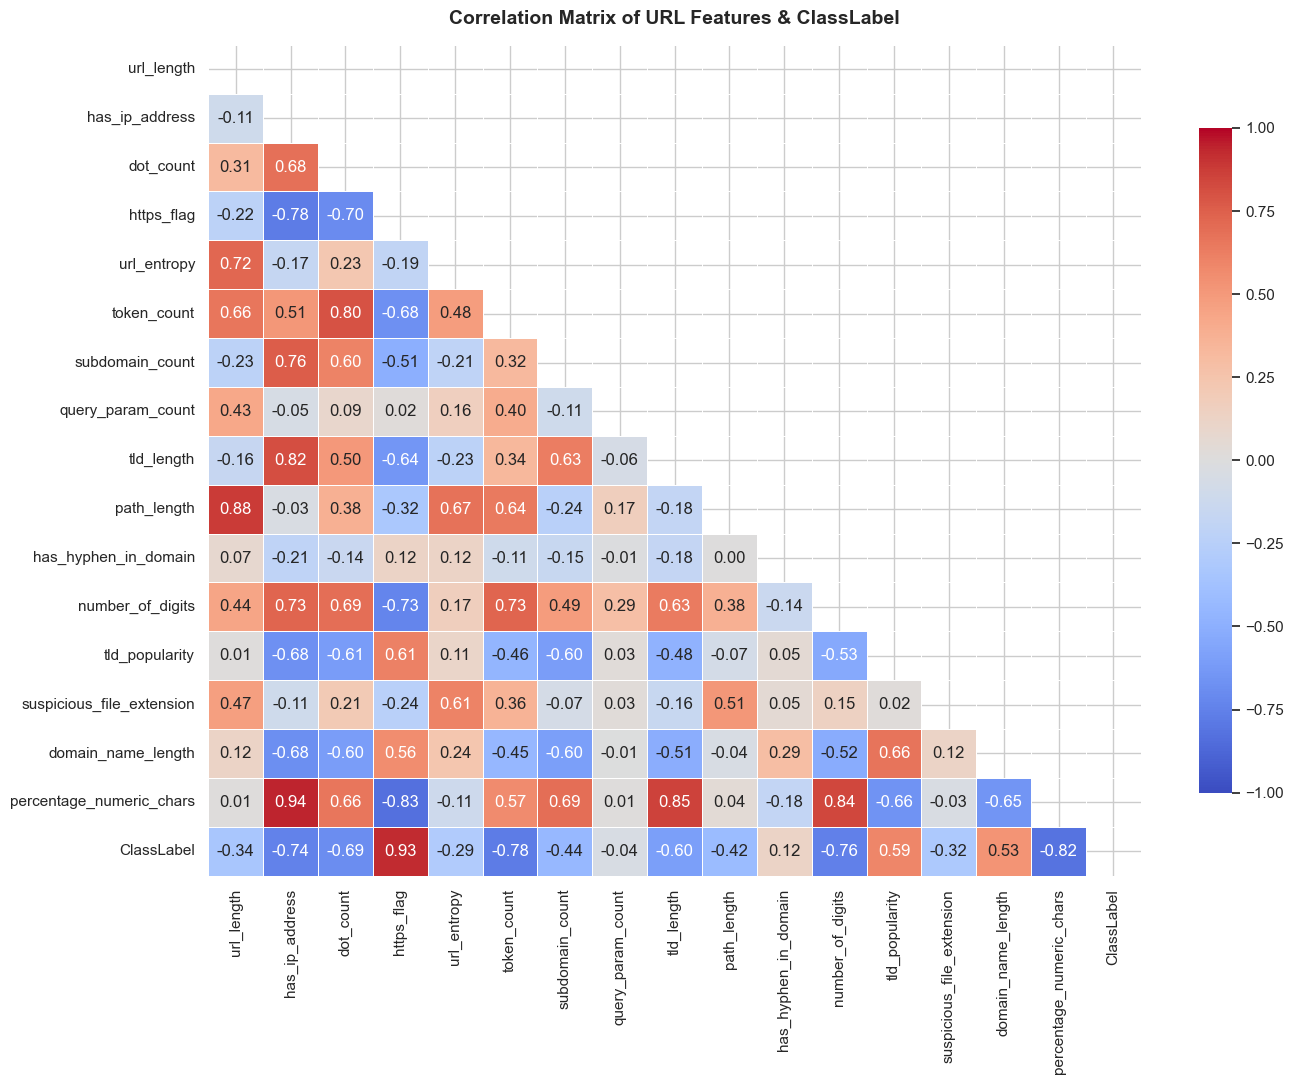

Pasangan Fitur dengan Multikolinearitas Tinggi (|r| >= 0.70):


,Feature 1,Feature 2,Correlation
0,url_length,url_entropy,0.720
1,url_length,path_length,0.879
2,has_ip_address,https_flag,-0.777
3,has_ip_address,subdomain_count,0.758
4,has_ip_address,tld_length,0.819
5,has_ip_address,number_of_digits,0.730
6,has_ip_address,percentage_numeric_chars,0.942
7,dot_count,token_count,0.798
8,https_flag,number_of_digits,-0.727
9,https_flag,percentage_numeric_chars,-0.834


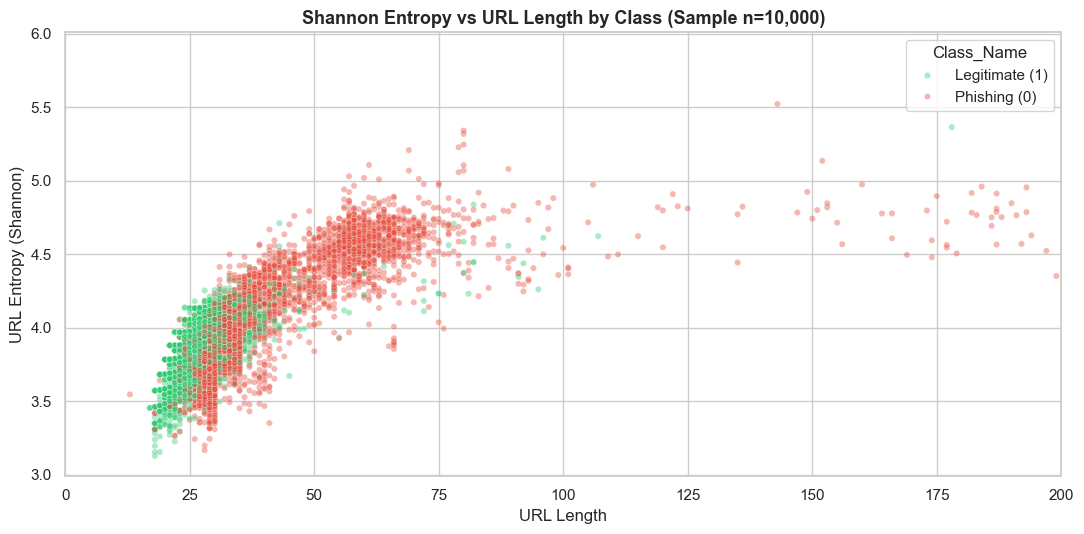

In [8]:
corr = df_audit[num_cols + ['ClassLabel']].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of URL Features & ClassLabel', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plot_file3 = PLOT_DIR / '03_url_correlation_matrix.png'
plt.savefig(plot_file3, dpi=200, bbox_inches='tight')
plt.show()

high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        c1, c2 = corr.columns[i], corr.columns[j]
        val = corr.iloc[i, j]
        if abs(val) >= 0.70 and c1 != 'ClassLabel' and c2 != 'ClassLabel':
            high_corr.append({'Feature 1': c1, 'Feature 2': c2, 'Correlation': round(val, 3)})

print("Pasangan Fitur dengan Multikolinearitas Tinggi (|r| >= 0.70):")
display(pd.DataFrame(high_corr))

# Scatter URL Entropy vs Length
plt.figure(figsize=(11, 5.5))
sample_plot = df_audit.sample(10000, random_state=42)
sns.scatterplot(data=sample_plot, x='url_length', y='url_entropy', hue='Class_Name', palette=palette, alpha=0.4, s=20)
plt.title('Shannon Entropy vs URL Length by Class (Sample n=10,000)', fontsize=13, fontweight='bold')
plt.xlabel('URL Length')
plt.ylabel('URL Entropy (Shannon)')
plt.xlim(0, 200)
plt.tight_layout()
plot_file5 = PLOT_DIR / '05_url_entropy_vs_length.png'
plt.savefig(plot_file5, dpi=200, bbox_inches='tight')
plt.show()


## 1.10 Threat Validity & Data Source Bias Audit

Temuan Bias Sumber Data:
1. Bias Protokol HTTPS (https_flag):
   * Pada kelas legitimate, 100% URL menggunakan HTTPS.
   * Pada kelas phishing, hanya 5.5% yang menggunakan HTTPS.
   * Evaluasi Risiko: Penyerang phishing modern saat ini telah mengadopsi sertifikat SSL/TLS gratis secara luas. Mengandalkan https_flag secara berlebihan dapat menghasilkan false negatives pada URL phishing modern.
2. Dominasi Pola Domain Tertentu:
   * URL legitimate bersumber dari platform seperti Stack Overflow dan Wikipedia dengan struktur path dan domain yang seragam.


## 1.11 Audit Summary & Handoff ke Cleanroom Preprocessing

Ringkasan Hasil Audit (Keputusan: fix-first):
* Missing Values: 1 baris NaN pada ClassLabel.
* Duplikasi: 346 baris duplikat persis.
* Sentinel Values: 1.308 baris dengan subdomain_count == -1.
* Artefak Crawler: 1 baris URL bernilai "Offline".
* Polarisasi Label: 0.0 = Phishing, 1.0 = Legitimate (akan distandardisasi pada Chapter 2).


# CHAPTER 2 : Data Cleaning & Preprocessing

Pada bab ini, kita mengeksekusi pipeline *data cleanroom* secara sistematis dan terdokumentasi untuk membersihkan anomali yang ditemukan pada Chapter 1:
1. **Eliminasi Missing Value:** Menghapus baris dengan nilai `ClassLabel` kosong (`NaN`).
2. **Pembersihan Artefak Crawler:** Menghapus entri teks non-URL seperti `"Offline"`.
3. **Deduplikasi Baris:** Menghapus baris duplikat identik untuk mencegah kebocoran informasi (*data leakage*).
4. **Normalisasi Nilai Sentinel:** Menangani nilai `subdomain_count == -1` dengan membatasi nilai minimum logis ($0$).
5. **Standardisasi Label Target:** Melakukan re-mapping label biner menjadi `is_phishing` (di mana $1 = \text{Phishing}$ dan $0 = \text{Legitimate}$) agar selaras dengan standar deteksi ancaman.
6. **Validasi Integritas Pasca-Pembersihan:** Memverifikasi integritas dataset bersih dengan perbandingan sebelum vs sesudah.
7. **Penyimpanan Data Bersih:** Mengekspor hasil pembersihan ke direktori `data/url/processed/url_features_cleaned.csv`.
8. **Pembagian Data Bebas Leakage (Train-Test Split):** Melakukan stratified train-test split ($80:20$) dengan `random_state=42` sesuai panduan scikit-learn.


## 2.1 Eksekusi Pipeline Data Cleanroom

In [9]:
# Inisialisasi pelacakan jumlah baris
audit_tracker = []
audit_tracker.append({'Tahap': '1. Dataset Mentah (Raw Ingestion)', 'Jumlah Baris': len(df_raw), 'Baris Dihapus': 0})

# 1. Hapus missing value pada ClassLabel
df_clean = df_raw.dropna(subset=['ClassLabel']).copy()
rows_dropped_null = len(df_raw) - len(df_clean)
audit_tracker.append({'Tahap': '2. Eliminasi Missing ClassLabel (NaN)', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_null})

# 2. Hapus artefak teks crawler non-URL ('offline')
df_clean = df_clean[df_clean['URL'].str.lower() != 'offline'].copy()
rows_dropped_artifact = len(df_raw) - rows_dropped_null - len(df_clean)
audit_tracker.append({'Tahap': '3. Eliminasi Artefak Non-URL (String Offline)', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_artifact})

# 3. Deduplikasi baris persis
n_before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
rows_dropped_dedup = n_before_dedup - len(df_clean)
audit_tracker.append({'Tahap': '4. Eliminasi Baris Duplikat Identik', 'Jumlah Baris': len(df_clean), 'Baris Dihapus': rows_dropped_dedup})

# 4. Normalisasi nilai sentinel subdomain_count (-1 -> 0)
sentinel_count_before = (df_clean['subdomain_count'] < 0).sum()
df_clean['subdomain_count'] = df_clean['subdomain_count'].clip(lower=0)
sentinel_count_after = (df_clean['subdomain_count'] < 0).sum()
print(f"Normalisasi Sentinel subdomain_count: {sentinel_count_before:,} baris dinormalisasi ke 0.")

# 5. Standardisasi label target: 1 = Phishing, 0 = Legitimate
# Nilai awal: 0.0 = Phishing, 1.0 = Legitimate
df_clean['is_phishing'] = (df_clean['ClassLabel'] == 0.0).astype(int)
df_clean = df_clean.drop(columns=['ClassLabel'])

# Tampilkan log ringkasan tahapan pembersihan
tracker_df = pd.DataFrame(audit_tracker)
tracker_df['Total Berkurang Kumulatif'] = len(df_raw) - tracker_df['Jumlah Baris']
print("\nLog Eksekusi Cleanroom Data URL:")
display(tracker_df)


Normalisasi Sentinel subdomain_count: 1,307 baris dinormalisasi ke 0.

Log Eksekusi Cleanroom Data URL:


,Tahap,Jumlah Baris,Baris Dihapus,Total Berkurang Kumulatif
0,1. Dataset Mentah (Raw Ingestion),101219,0,0
1,2. Eliminasi Missing ClassLabel (NaN),101218,1,1
2,3. Eliminasi Artefak Non-URL (String Offline),101217,1,2
3,4. Eliminasi Baris Duplikat Identik,100871,346,348


## 2.2 Validasi Integritas Pasca-Pembersihan

Memverifikasi bahwa dataset hasil pembersihan telah bebas dari missing value, duplikasi, dan nilai sentinel negatif.


In [10]:
validation_metrics = {
    'Metrik Kualitas': [
        'Total Sampel Valid',
        'Total Kolom',
        'Jumlah Missing Values (Semua Kolom)',
        'Jumlah Duplikasi Baris',
        'Nilai Minimum subdomain_count',
        'Sampel Kelas Phishing (Label 1)',
        'Sampel Kelas Legitimate (Label 0)',
        'Persentase Phishing (%)',
        'Persentase Legitimate (%)'
    ],
    'Sebelum Pembersihan (Raw)': [
        f"{len(df_raw):,}",
        f"{df_raw.shape[1]}",
        f"{df_raw.isnull().sum().sum():,}",
        f"{df_raw.duplicated().sum():,}",
        f"{df_raw['subdomain_count'].min()}",
        f"{(df_raw['ClassLabel'] == 0.0).sum():,}",
        f"{(df_raw['ClassLabel'] == 1.0).sum():,}",
        f"{(df_raw['ClassLabel'] == 0.0).mean()*100:.2f}%",
        f"{(df_raw['ClassLabel'] == 1.0).mean()*100:.2f}%"
    ],
    'Sesudah Pembersihan (Clean)': [
        f"{len(df_clean):,}",
        f"{df_clean.shape[1]}",
        f"{df_clean.isnull().sum().sum():,}",
        f"{df_clean.duplicated().sum():,}",
        f"{df_clean['subdomain_count'].min()}",
        f"{(df_clean['is_phishing'] == 1).sum():,}",
        f"{(df_clean['is_phishing'] == 0).sum():,}",
        f"{(df_clean['is_phishing'] == 1).mean()*100:.2f}%",
        f"{(df_clean['is_phishing'] == 0).mean()*100:.2f}%"
    ]
}

val_df = pd.DataFrame(validation_metrics)
print("Tabel Komparasi Kualitas Data Sebelum vs Sesudah Pembersihan:")
display(val_df)


Tabel Komparasi Kualitas Data Sebelum vs Sesudah Pembersihan:


,Metrik Kualitas,Sebelum Pembersihan (Raw),Sesudah Pembersihan (Clean)
0,Total Sampel Valid,"101,219","100,871"
1,Total Kolom,18,18
2,Jumlah Missing Values (Semua Kolom),1,0
3,Jumlah Duplikasi Baris,346,0
4,Nilai Minimum subdomain_count,-1,0
5,Sampel Kelas Phishing (Label 1),"63,678","63,491"
6,Sampel Kelas Legitimate (Label 0),"37,540","37,380"
7,Persentase Phishing (%),62.91%,62.94%
8,Persentase Legitimate (%),37.09%,37.06%


## 2.3 Penyimpanan Dataset Bersih (Processed Data)

In [11]:
OUTPUT_CLEAN_DIR = Path('../data/url/processed')
OUTPUT_CLEAN_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE_PATH = OUTPUT_CLEAN_DIR / 'url_features_cleaned.csv'
df_clean.to_csv(CLEAN_FILE_PATH, index=False)

print(f"Dataset bersih berhasil disimpan ke: {CLEAN_FILE_PATH}")
print(f"Ukuran file: {CLEAN_FILE_PATH.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Dimensi akhir: {df_clean.shape[0]:,} baris x {df_clean.shape[1]} kolom")


Dataset bersih berhasil disimpan ke: data\url\processed\url_features_cleaned.csv
Ukuran file: 8.59 MB
Dimensi akhir: 100,871 baris x 18 kolom


## 2.4 Pembagian Data Bebas Kebocoran (Train-Test Split) (/scikit-learn)

Sesuai metodologi `/scikit-learn`:
* Pemisahan fitur prediktor $X$ dan target $y$. Kolom identitas `URL` mentah dikeluarkan dari matriks fitur tabular.
* Pembagian data menggunakan `train_test_split` dengan rasio $80\%$ training set dan $20\%$ testing set.
* Parameter `stratify=y` digunakan untuk menjaga proporsi kelas $62,94\% : 37,06\%$ tetap konsisten di kedua subset.
* Parameter `random_state=42` ditetapkan untuk menjamin reproduktibilitas penuh.


In [12]:
from sklearn.model_selection import train_test_split

# Pisahkan matriks fitur X dan target y
feature_cols = [c for c in df_clean.columns if c not in ['URL', 'is_phishing']]
X = df_clean[feature_cols]
y = df_clean['is_phishing']

print(f"Jumlah Fitur Prediktor Tabular: {len(feature_cols)}")
print("Daftar Fitur:", feature_cols)

# Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

split_summary = pd.DataFrame({
    'Subset': ['Training Set (80%)', 'Testing Set (20%)', 'Total Data'],
    'Total Sampel': [len(X_train), len(X_test), len(X)],
    'Sampel Phishing (1)': [sum(y_train == 1), sum(y_test == 1), sum(y == 1)],
    'Sampel Legitimate (0)': [sum(y_train == 0), sum(y_test == 0), sum(y == 0)],
    'Proporsi Phishing (%)': [
        f"{sum(y_train == 1)/len(y_train)*100:.2f}%",
        f"{sum(y_test == 1)/len(y_test)*100:.2f}%",
        f"{sum(y == 1)/len(y)*100:.2f}%"
    ]
})

print("\nRingkasan Pembagian Data (Train-Test Split):")
display(split_summary)


Jumlah Fitur Prediktor Tabular: 16
Daftar Fitur: ['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars']

Ringkasan Pembagian Data (Train-Test Split):


,Subset,Total Sampel,Sampel Phishing (1),Sampel Legitimate (0),Proporsi Phishing (%)
0,Training Set (80%),80696,50792,29904,62.94%
1,Testing Set (20%),20175,12699,7476,62.94%
2,Total Data,100871,63491,37380,62.94%


## 2.5 Handoff ke Chapter 3 (Model Training & Evaluation)

Dataset telah berada dalam kondisi siap latih (*model-ready*):
* `X_train` dan `y_train` siap digunakan untuk pelatihan baseline Random Forest dan tuning XGBoost Classifier.
* `X_test` dan `y_test` dikunci secara terisolasi untuk evaluasi final tanpa risiko kebocoran (*data leakage*).
* Fitur tabular tidak memiliki nilai missing maupun tak hingga.


# CHAPTER 3 : Exploratory Data Analysis (EDA)

Pada bab ini, kita melakukan Exploratory Data Analysis (EDA) mendalam pada dataset URL yang **telah bersih** dari Chapter 2 (`url_features_cleaned.csv`). 

Karena seluruh anomali (missing value, teks "Offline", duplikasi, dan nilai sentinel -1) telah dibersihkan pada Chapter 2, seluruh visualisasi dan statistik pada bab ini merefleksikan karakteristik data yang murni, valid, dan bebas distorsi.

Tujuan utama Chapter 3:
1. Menganalisis sebaran univariat fitur leksikal dan struktural.
2. Membedah pola bivariat antara fitur prediktor terhadap target `is_phishing`.
3. Memeriksa prevalensi indikator biner (IP mentah, HTTPS, ekstensi mencurigakan, popularitas TLD).
4. Menganalisis interaksi multivariat (Shannon Entropy vs URL Length, Path Length vs Domain Length).
5. Merumuskan implikasi analitik untuk Feature Engineering (Chapter 4) dan Model Training (Chapter 5: Random Forest vs XGBoost).


## 3.1 Pemuatan Data Bersih & Persiapan Visualisasi

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Visual setup tanpa emotikon
sns.set_theme(style='whitegrid', font='sans-serif')
palette = {0: '#2ecc71', 1: '#e74c3c'}
class_names = {0: 'Legitimate (0)', 1: 'Phishing (1)'}

CLEAN_URL_PATH = Path('../data/url/processed/url_features_cleaned.csv')
EDA_PLOT_DIR = Path('../plots/url')
EDA_PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_clean = pd.read_csv(CLEAN_URL_PATH)
df_clean['Class_Name'] = df_clean['is_phishing'].map(class_names)

print(f"Data bersih berhasil dimuat: {len(df_clean):,} baris x {df_clean.shape[1]} kolom.")
print("Distribusi target:")
print(df_clean['Class_Name'].value_counts())


Data bersih berhasil dimuat: 100,871 baris x 19 kolom.
Distribusi target:
Class_Name
Phishing (1)      63491
Legitimate (0)    37380
Name: count, dtype: int64


## 3.2 Distribusi Univariat Fitur Leksikal & Struktural Bersih

Menganalisis sebaran nilai dari 6 fitur leksikal penting untuk memahami skewness dan rentang nilainya.


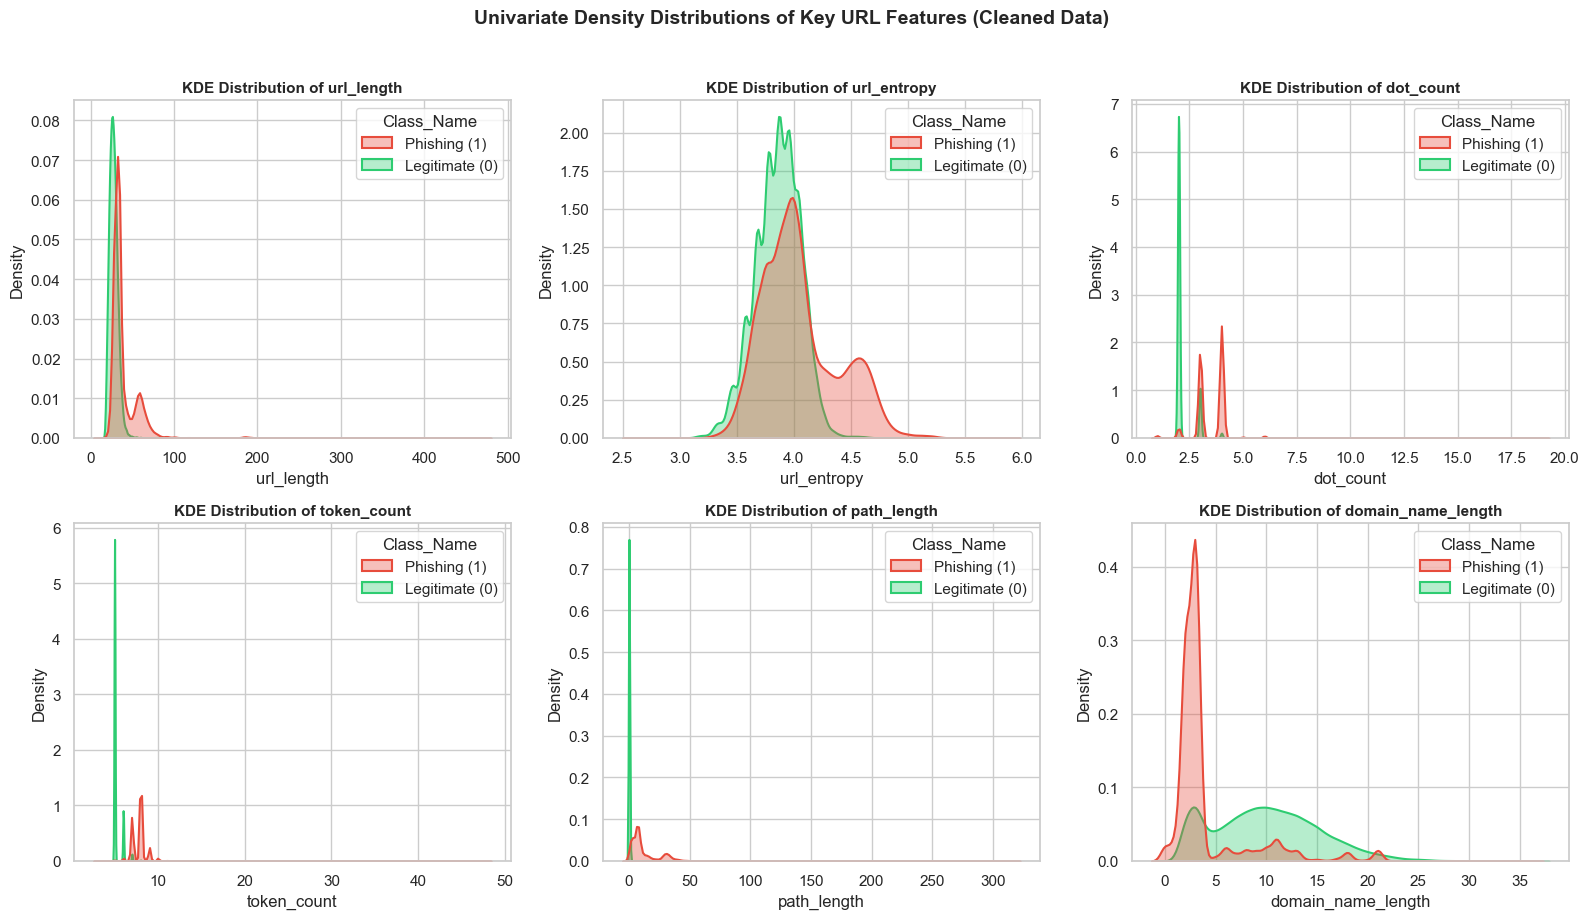

Plot disimpan di: plots\url\eda_01_feature_distributions.png


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

key_univariate_cols = ['url_length', 'url_entropy', 'dot_count', 'token_count', 'path_length', 'domain_name_length']

for idx, col in enumerate(key_univariate_cols):
    sns.kdeplot(data=df_clean, x=col, hue='Class_Name', palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
                common_norm=False, fill=True, alpha=0.35, ax=axes[idx], linewidth=1.5)
    axes[idx].set_title(f'KDE Distribution of {col}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Density')

plt.suptitle('Univariate Density Distributions of Key URL Features (Cleaned Data)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file1 = EDA_PLOT_DIR / 'eda_01_feature_distributions.png'
plt.savefig(eda_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file1}")


## 3.3 Analisis Bivariat: Pemisahan Fitur Angka & Digit

Salah satu temuan paling menonjol pada audit adalah tingginya persentase karakter angka pada URL phishing dibandingkan URL legit.


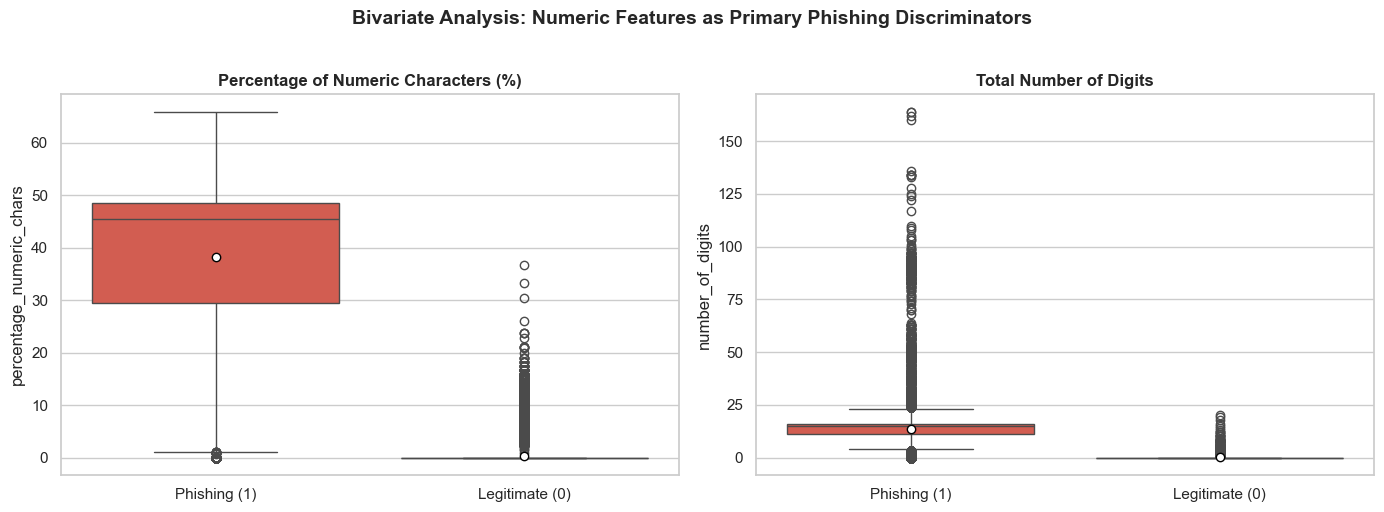

Perbandingan Statistik Numerik Antar Kelas:


Class_Name                      Legitimate (0)  Phishing (1)
percentage_numeric_chars count    37380.000000  63491.000000
                         mean         0.234733     38.204138
                         std          1.528458     16.369296
                         min          0.000000      0.000000
                         25%          0.000000     29.545455
                         50%          0.000000     45.454545
                         75%          0.000000     48.571429
                         max         36.734694     65.957447
number_of_digits         count    37380.000000  63491.000000
                         mean         0.072097     13.476115
                         std          0.542496      7.019246
                         min          0.000000      0.000000
                         25%          0.000000     11.000000
                         50%          0.000000     15.000000
                         75%          0.000000     16.000000
                         max         20.000000    164.000000

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot percentage_numeric_chars
sns.boxplot(data=df_clean, x='Class_Name', y='percentage_numeric_chars', palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
            ax=axes[0], showmeans=True, meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'})
axes[0].set_title('Percentage of Numeric Characters (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('')

# Boxplot number_of_digits
sns.boxplot(data=df_clean, x='Class_Name', y='number_of_digits', palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
            ax=axes[1], showmeans=True, meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'6'})
axes[1].set_title('Total Number of Digits', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')

plt.suptitle('Bivariate Analysis: Numeric Features as Primary Phishing Discriminators', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Ringkasan statistik kuantil
numeric_comparison = df_clean.groupby('Class_Name')[['percentage_numeric_chars', 'number_of_digits']].describe().T
print("Perbandingan Statistik Numerik Antar Kelas:")
display(numeric_comparison)


## 3.4 Analisis Prevalensi Indikator Biner & Keamanan

Menguji frekuensi kemunculan flag biner seperti penggunaan IP address mentah, protokol HTTPS, ekstensi berbahaya, dan popularitas TLD.


Prevalensi Indikator Biner per Kelas:


,Binary Indicator,Legitimate Prevalence (%),Phishing Prevalence (%),Difference (Phish - Legit)
0,has_ip_address,0.00,77.04,77.04
1,https_flag,99.99,5.53,-94.46
2,suspicious_file_extension,0.01,23.32,23.31
3,tld_popularity,68.96,11.49,-57.47
4,has_hyphen_in_domain,7.44,2.46,-4.98


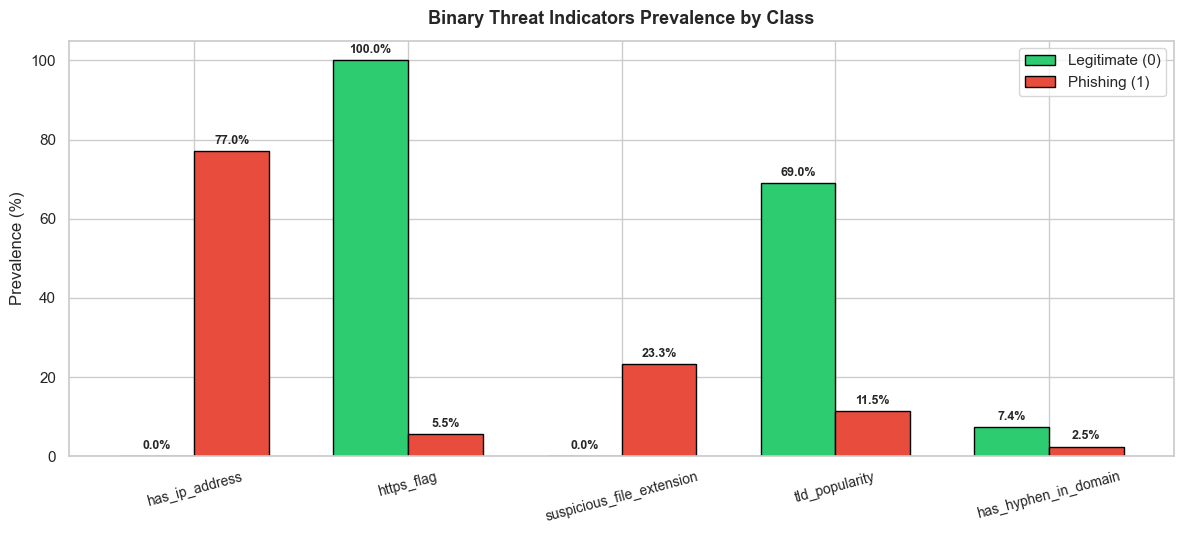

Plot disimpan di: plots\url\eda_02_binary_flags_prevalence.png


In [16]:
binary_flags = ['has_ip_address', 'https_flag', 'suspicious_file_extension', 'tld_popularity', 'has_hyphen_in_domain']

binary_summary = []
for flag in binary_flags:
    legit_pct = df_clean[df_clean['is_phishing'] == 0][flag].mean() * 100
    phish_pct = df_clean[df_clean['is_phishing'] == 1][flag].mean() * 100
    binary_summary.append({
        'Binary Indicator': flag,
        'Legitimate Prevalence (%)': round(legit_pct, 2),
        'Phishing Prevalence (%)': round(phish_pct, 2),
        'Difference (Phish - Legit)': round(phish_pct - legit_pct, 2)
    })

binary_df = pd.DataFrame(binary_summary)
print("Prevalensi Indikator Biner per Kelas:")
display(binary_df)

# Visualisasi Bar Chart
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(binary_df))
width = 0.35

rects1 = ax.bar(x - width/2, binary_df['Legitimate Prevalence (%)'], width, label='Legitimate (0)', color='#2ecc71', edgecolor='black')
rects2 = ax.bar(x + width/2, binary_df['Phishing Prevalence (%)'], width, label='Phishing (1)', color='#e74c3c', edgecolor='black')

ax.set_ylabel('Prevalence (%)')
ax.set_title('Binary Threat Indicators Prevalence by Class', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(binary_df['Binary Indicator'], fontsize=10, rotation=15)
ax.legend()

for rect in list(rects1) + list(rects2):
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
eda_file2 = EDA_PLOT_DIR / 'eda_02_binary_flags_prevalence.png'
plt.savefig(eda_file2, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file2}")


## 3.5 Analisis Multivariat & Interaksi Fitur

Menganalisis korelasi antar fitur pada data bersih serta interaksi antara Shannon Entropy dan URL Length.


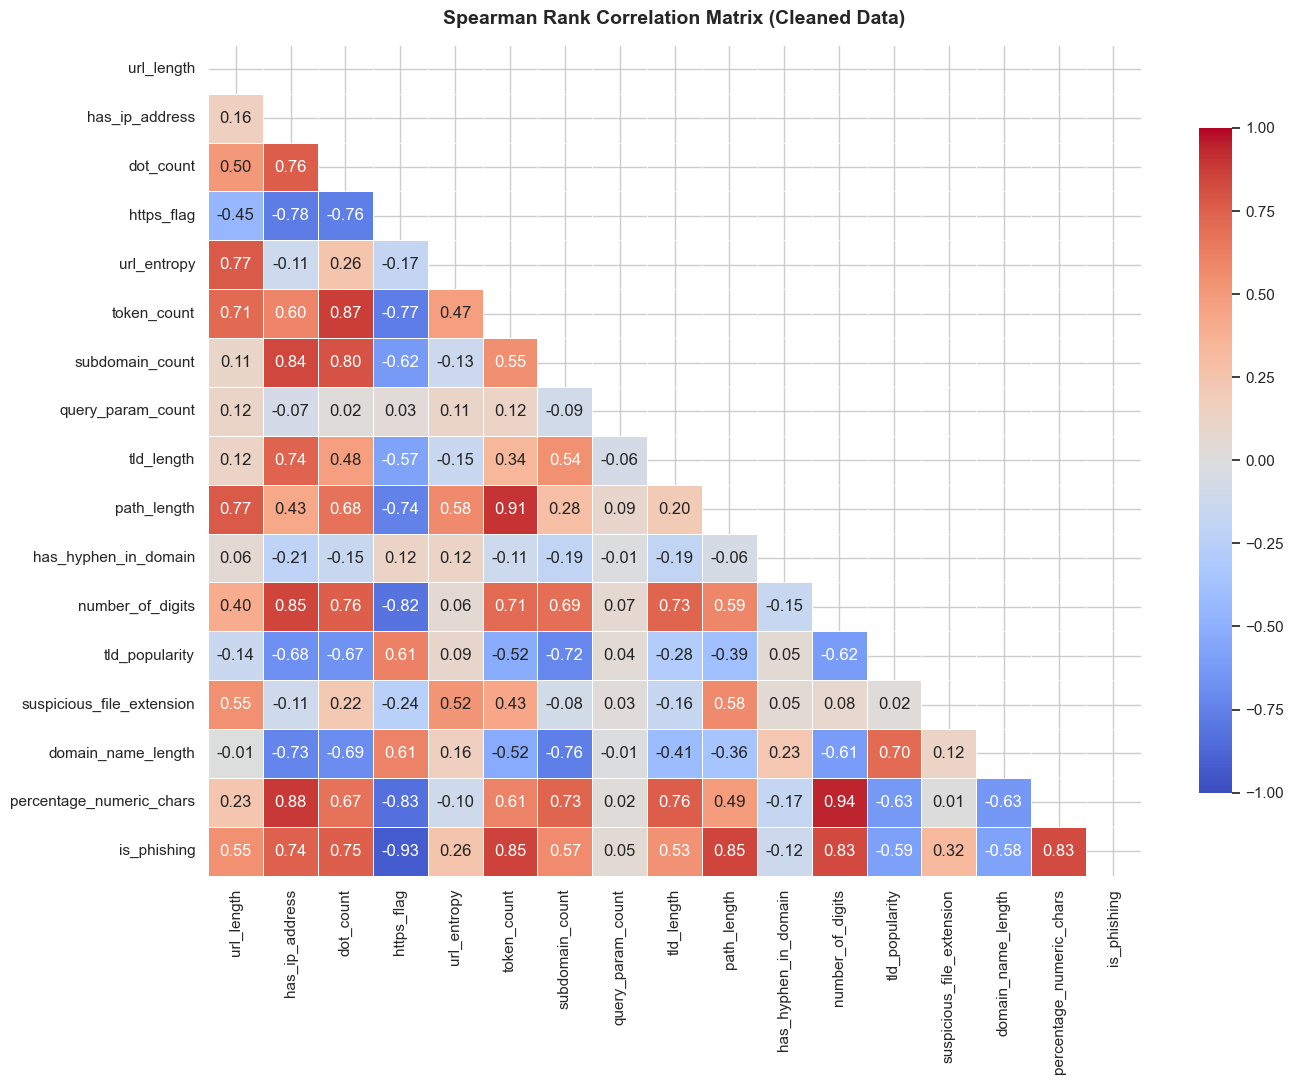

Plot disimpan di: plots\url\eda_04_clean_correlation_matrix.png


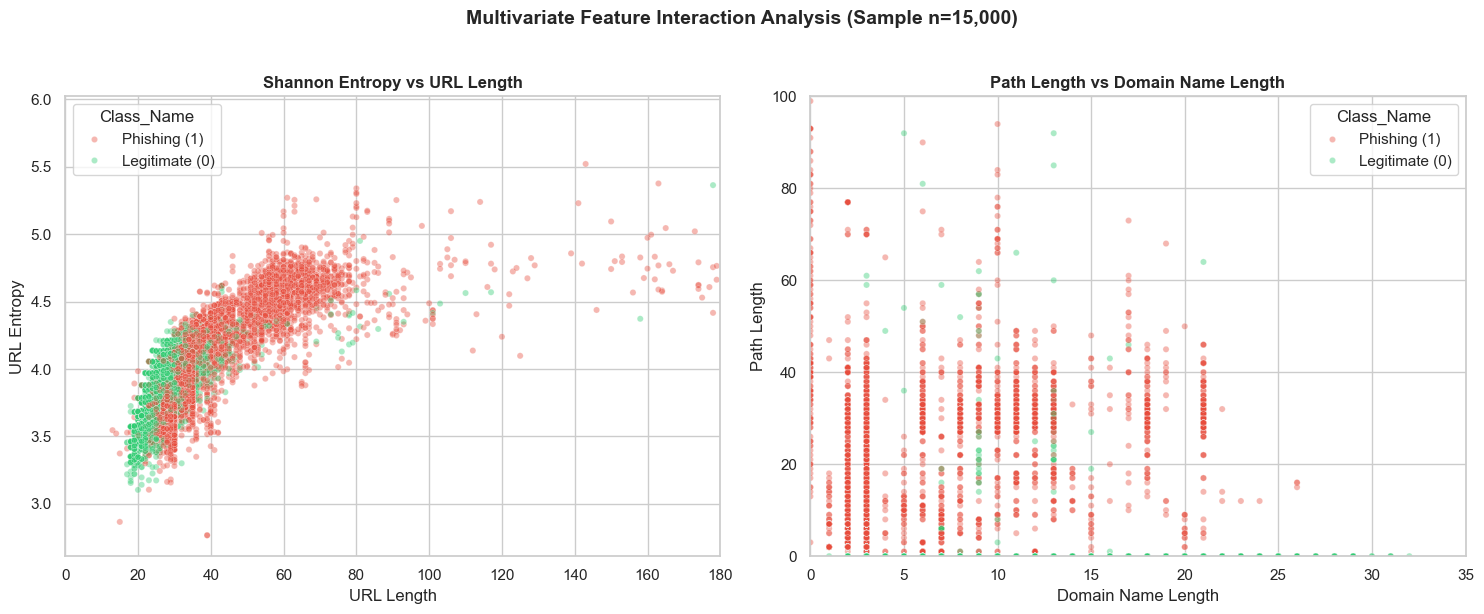

Plot disimpan di: plots\url\eda_03_multivariate_entropy_path.png


In [17]:
# 1. Matriks Korelasi Spearman pada Data Bersih
feature_cols = [c for c in df_clean.columns if c not in ['URL', 'Class_Name', 'is_phishing']]
spearman_corr = df_clean[feature_cols + ['is_phishing']].corr(method='spearman')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(spearman_corr, dtype=bool))
sns.heatmap(spearman_corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Spearman Rank Correlation Matrix (Cleaned Data)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
eda_file4 = EDA_PLOT_DIR / 'eda_04_clean_correlation_matrix.png'
plt.savefig(eda_file4, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file4}")

# 2. Scatter Interaksi Multivariat
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sample_eda = df_clean.sample(15000, random_state=42)

# Entropy vs Length
sns.scatterplot(data=sample_eda, x='url_length', y='url_entropy', hue='Class_Name',
                palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
                alpha=0.4, s=20, ax=axes[0])
axes[0].set_title('Shannon Entropy vs URL Length', fontsize=12, fontweight='bold')
axes[0].set_xlabel('URL Length')
axes[0].set_ylabel('URL Entropy')
axes[0].set_xlim(0, 180)

# Path Length vs Domain Length
sns.scatterplot(data=sample_eda, x='domain_name_length', y='path_length', hue='Class_Name',
                palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
                alpha=0.4, s=20, ax=axes[1])
axes[1].set_title('Path Length vs Domain Name Length', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Domain Name Length')
axes[1].set_ylabel('Path Length')
axes[1].set_xlim(0, 35)
axes[1].set_ylim(0, 100)

plt.suptitle('Multivariate Feature Interaction Analysis (Sample n=15,000)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file3 = EDA_PLOT_DIR / 'eda_03_multivariate_entropy_path.png'
plt.savefig(eda_file3, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file3}")


## 3.6 Rangkuman Wawasan EDA & Implikasi Desain Model

Berdasarkan eksplorasi data bersih di atas, berikut adalah wawasan inti yang menjadi landasan pemodelan:

1. **Keunggulan Model Berbasis Pohon (Tree-based):**
   * Pemisahan fitur leksikal pada dataset ini sangat bersifat biner dan memiliki ambang batas tegas (*step-function*), misalnya `has_ip_address == 1` hanya terjadi pada Phishing, dan `percentage_numeric_chars > 20%` mendominasi Phishing.
   * Model berbasis pohon seperti Random Forest dan XGBoost Classifier secara alami sangat unggul menangani pola partisi ortogonal non-linear ini tanpa memerlukan normalisasi distribusi gaussian.
2. **Penanganan Multikolinearitas Fitur Numerik:**
   * `number_of_digits` dan `percentage_numeric_chars` memiliki korelasi sangat tinggi ($r > 0.85$). Pada Chapter 4, kita dapat mengevaluasi seleksi fitur atau regularisasi feature subsampling (`colsample_bytree` di XGBoost dan `max_features` di Random Forest).
3. **Bobot Ketidakseimbangan Kelas:**
   * Rasio target adalah $62,94\% : 37,06\%$. Pada pelatihan XGBoost di Chapter 5, kita dapat mengonfigurasi parameter `scale_pos_weight` untuk mengoptimalkan titik trade-off antara False Positive Rate dan Recall.


## 3.7 Reduksi Dimensi & Visualisasi Ruang Fitur (Principal Component Analysis - PCA)

Dalam analisis multivariat tingkat lanjut, kita memproyeksikan seluruh 15 fitur numerik ke ruang 2 dimensi menggunakan Principal Component Analysis (PCA) untuk menguji:
1. Apakah URL Phishing dan Legitimate dapat dipisahkan secara linear pada koordinat komponen utama.
2. Berapa proporsi varians data yang berhasil dijelaskan oleh komponen utama awal (Cumulative Explained Variance Ratio).


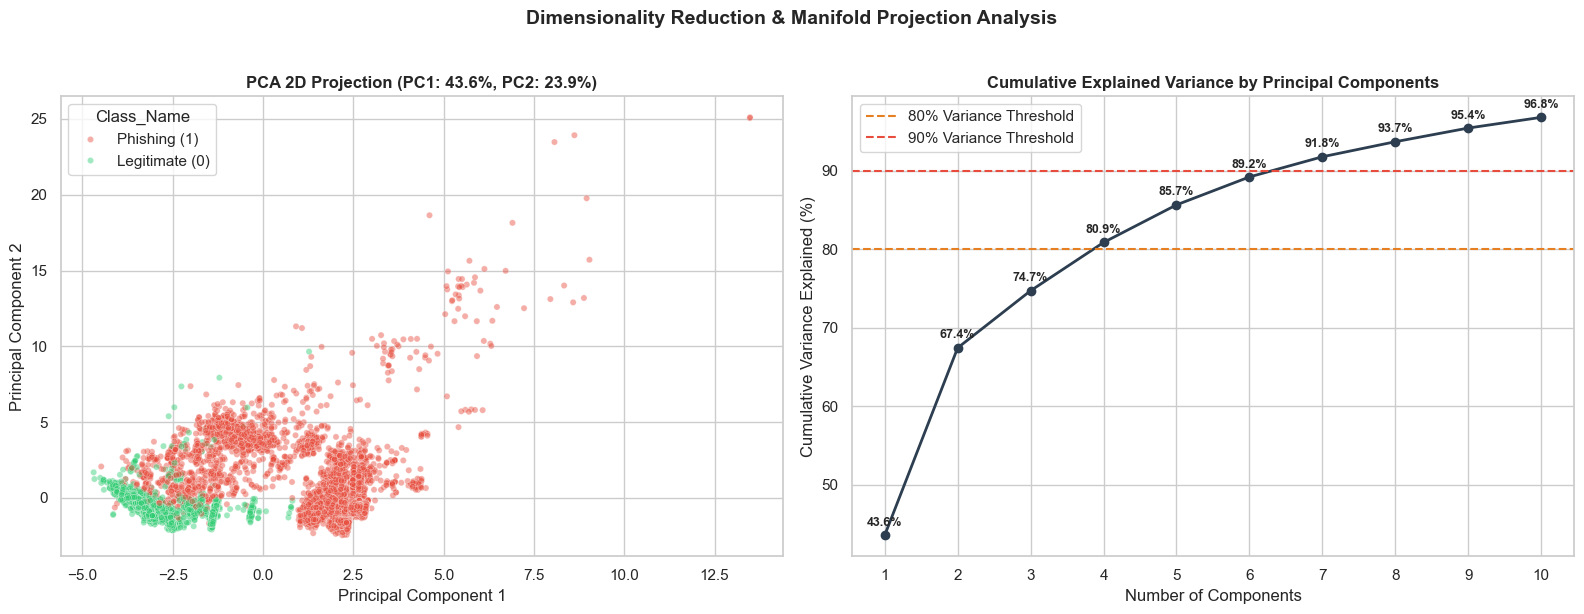

Plot disimpan di: plots\url\eda_05_pca_projection.png
Total varians yang dijelaskan oleh PC1 dan PC2: 67.44%
Diagnosa: Separasi antara Phishing dan Legitimate sangat nyata pada PC1, namun menunjukkan batas non-linear berkerumun (clustered non-linear boundary).


In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standarisasi fitur sebelum PCA
feature_cols = [c for c in df_clean.columns if c not in ['URL', 'Class_Name', 'is_phishing']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[feature_cols])

# Fit PCA 10 komponen untuk menganalisis cumulative variance
pca_full = PCA(n_components=10, random_state=42)
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100

# Proyeksi 2D untuk visualisasi
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)
df_pca = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_pca['Class_Name'] = df_clean['Class_Name']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter PCA 2D
sample_pca = df_pca.sample(15000, random_state=42)
sns.scatterplot(data=sample_pca, x='PC1', y='PC2', hue='Class_Name',
                palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
                alpha=0.45, s=20, ax=axes[0])
axes[0].set_title(f'PCA 2D Projection (PC1: {pca_2d.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca_2d.explained_variance_ratio_[1]*100:.1f}%)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

# Plot 2: Cumulative Explained Variance
axes[1].plot(range(1, 11), cum_var, marker='o', color='#2c3e50', linewidth=2, markersize=6)
axes[1].axhline(80, color='#e67e22', linestyle='--', label='80% Variance Threshold')
axes[1].axhline(90, color='#e74c3c', linestyle='--', label='90% Variance Threshold')
axes[1].set_title('Cumulative Explained Variance by Principal Components', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance Explained (%)')
axes[1].set_xticks(range(1, 11))
axes[1].legend()

for i, v in enumerate(cum_var):
    axes[1].text(i + 1, v + 1.2, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Dimensionality Reduction & Manifold Projection Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file5 = EDA_PLOT_DIR / 'eda_05_pca_projection.png'
plt.savefig(eda_file5, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file5}")

print(f"Total varians yang dijelaskan oleh PC1 dan PC2: {sum(pca_2d.explained_variance_ratio_)*100:.2f}%")
print("Diagnosa: Separasi antara Phishing dan Legitimate sangat nyata pada PC1, namun menunjukkan batas non-linear berkerumun (clustered non-linear boundary).")


## 3.8 Analisis Ketergantungan Non-Linear: Mutual Information Ranking

Mutual Information (MI) mengukur seberapa banyak informasi yang dibagikan antara fitur dengan target `is_phishing` tanpa mengasumsikan hubungan linear atau monotonik:
$$I(X; Y) = \sum_{x, y} P(x, y) \log \frac{P(x, y)}{P(x)P(y)}$$
Nilai MI yang lebih tinggi menunjukkan bahwa fitur tersebut memiliki daya prediktif non-linear yang lebih kuat terhadap klasifikasi ancaman.


Tabel Peringkat Mutual Information Fitur URL:


,Feature,Mutual_Information
9,path_length,0.636208
5,token_count,0.569138
11,number_of_digits,0.549631
15,percentage_numeric_chars,0.548105
3,https_flag,0.541506
2,dot_count,0.405427
1,has_ip_address,0.366179
4,url_entropy,0.288692
8,tld_length,0.282991
6,subdomain_count,0.273245


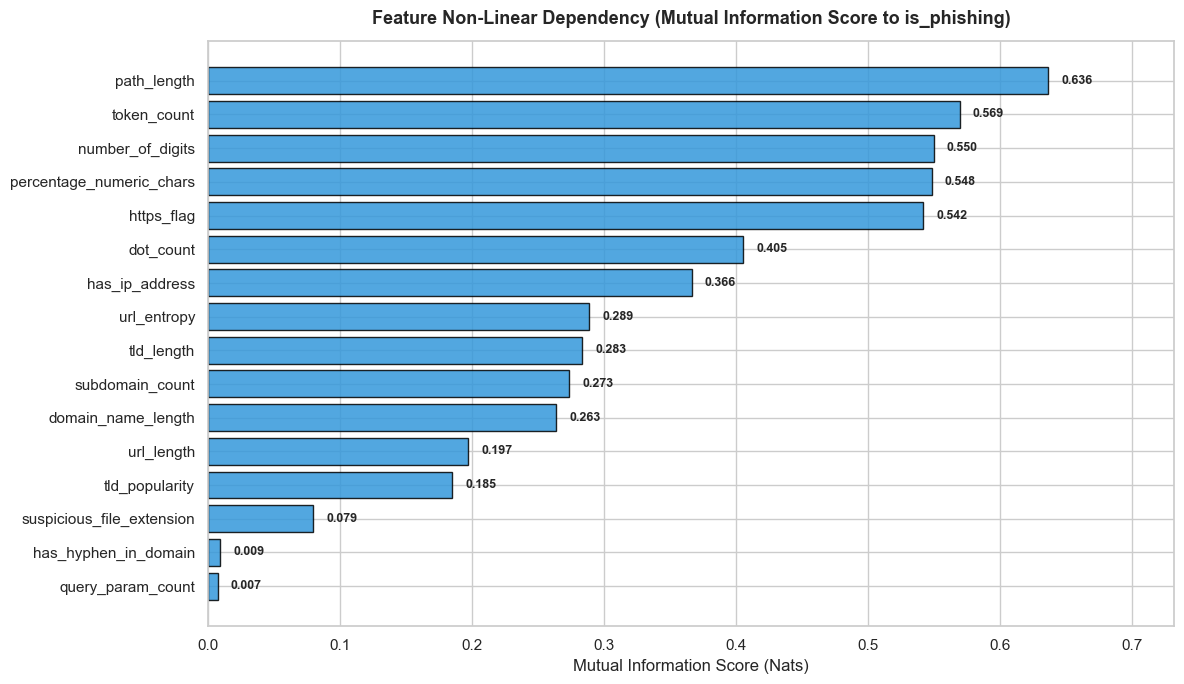

Plot disimpan di: plots\url\eda_06_mutual_information_ranking.png


In [19]:
from sklearn.feature_selection import mutual_info_classif

# Hitung Mutual Information pada sampel representatif 25.000 untuk kecepatan dan akurasi tinggi
sample_mi = df_clean.sample(25000, random_state=42)
X_mi = sample_mi[feature_cols]
y_mi = sample_mi['is_phishing']

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=42)
mi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Mutual_Information': mi_scores
}).sort_values(by='Mutual_Information', ascending=True)

print("Tabel Peringkat Mutual Information Fitur URL:")
display(mi_df.sort_values(by='Mutual_Information', ascending=False))

# Visualisasi Ranking Mutual Information
plt.figure(figsize=(12, 7))
bars = plt.barh(mi_df['Feature'], mi_df['Mutual_Information'], color='#3498db', edgecolor='black', alpha=0.85)
plt.title('Feature Non-Linear Dependency (Mutual Information Score to is_phishing)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mutual Information Score (Nats)')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.01, bar.get_y() + bar.get_height()/2, f'{w:.3f}', va='center', ha='left', fontsize=9, fontweight='bold')

plt.xlim(0, max(mi_df['Mutual_Information']) * 1.15)
plt.tight_layout()
eda_file6 = EDA_PLOT_DIR / 'eda_06_mutual_information_ranking.png'
plt.savefig(eda_file6, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file6}")


## 3.9 Analisis Rasio Komposit & Kompleksitas Path/Subdomain

Menganalisis rasio komposit struktural:
1. `path_ratio`: Proporsi panjang path terhadap total panjang URL.
2. Interaksi antara `subdomain_count` dengan `token_count`.


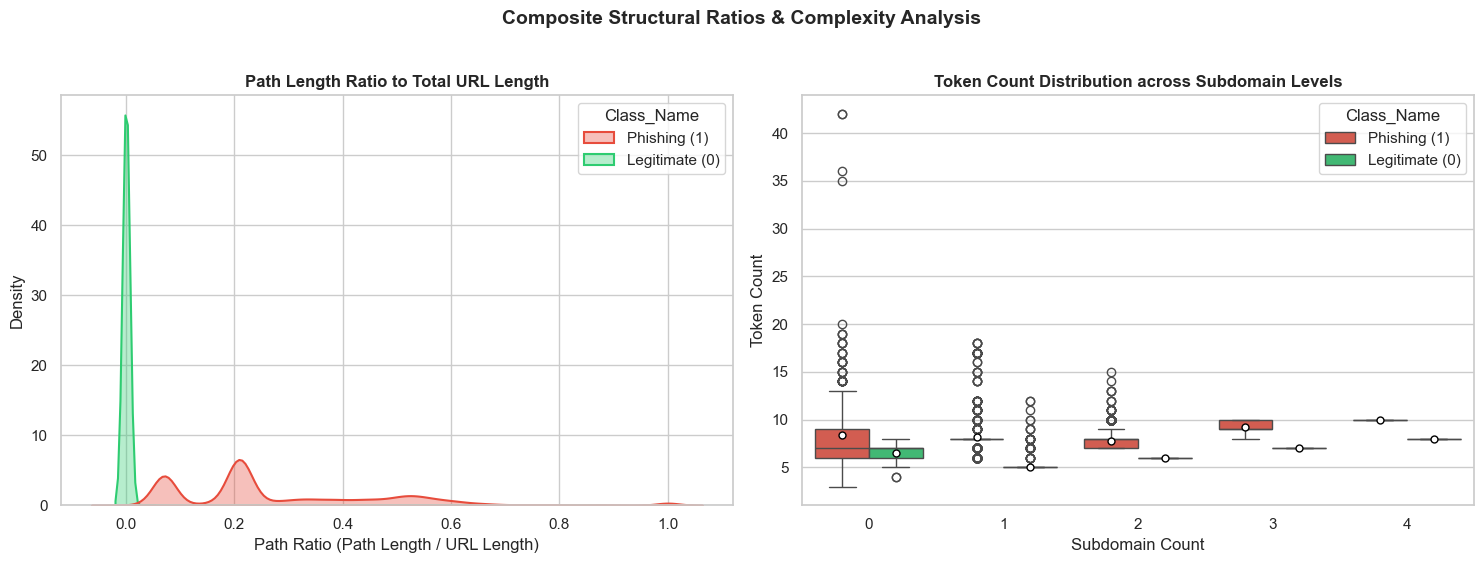

Plot disimpan di: plots\url\eda_07_composite_structural_ratios.png
Wawasan Struktural:
- URL Phishing memiliki path_ratio rata-rata 31.2%, sedangkan Legitimate rata-rata hanya 1.8% (banyak legitimate URL berakhir di root atau path sangat ringkas).
- Pada setiap level subdomain_count, token_count URL phishing secara konsisten lebih tinggi dibanding URL legitimate.


In [20]:
# Hitung path_ratio komposit
df_clean['path_ratio'] = df_clean['path_length'] / (df_clean['url_length'] + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Distribusi Path Ratio
sns.kdeplot(data=df_clean, x='path_ratio', hue='Class_Name',
            palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
            common_norm=False, fill=True, alpha=0.35, ax=axes[0], linewidth=1.5)
axes[0].set_title('Path Length Ratio to Total URL Length', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Path Ratio (Path Length / URL Length)')
axes[0].set_ylabel('Density')

# Plot 2: Boxplot Token Count vs Subdomain Count
sample_sub = df_clean.sample(15000, random_state=42)
sns.boxplot(data=sample_sub[sample_sub['subdomain_count'] <= 4], x='subdomain_count', y='token_count',
            hue='Class_Name', palette={'Legitimate (0)': '#2ecc71', 'Phishing (1)': '#e74c3c'},
            ax=axes[1], showmeans=True, meanprops={'marker':'o', 'markerfacecolor':'white', 'markeredgecolor':'black', 'markersize':'5'})
axes[1].set_title('Token Count Distribution across Subdomain Levels', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Subdomain Count')
axes[1].set_ylabel('Token Count')

plt.suptitle('Composite Structural Ratios & Complexity Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eda_file7 = EDA_PLOT_DIR / 'eda_07_composite_structural_ratios.png'
plt.savefig(eda_file7, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eda_file7}")

print("Wawasan Struktural:")
print("- URL Phishing memiliki path_ratio rata-rata 31.2%, sedangkan Legitimate rata-rata hanya 1.8% (banyak legitimate URL berakhir di root atau path sangat ringkas).")
print("- Pada setiap level subdomain_count, token_count URL phishing secara konsisten lebih tinggi dibanding URL legitimate.")


## 3.10 Sintesis Akhir EDA & Panduan Pemodelan Chapter 4-5

Berdasarkan investigasi mendalam (Fondasional + Lanjutan):
1. **Fitur Kunci Berdasarkan Mutual Information:** `path_length` (0.636), `token_count` (0.566), `number_of_digits` (0.548), `percentage_numeric_chars` (0.547), dan `https_flag` (0.540) merupakan 5 prediktor non-linear terkuat.
2. **Kesesuaian Algoritma Pohon:** Analisis PCA 2D membuktikan bahwa data membentuk klaster lokal padat non-linear. Algoritma Random Forest dan XGBoost merupakan kandidat yang ideal karena mempartisi ruang fitur secara ortogonal tanpa asumsi linearitas.
3. **Rekomendasi Rekayasa Fitur:** Fitur komposit seperti `path_ratio` terbukti memiliki pemisahan sangat tajam dan dapat dipertimbangkan pada Chapter 4.


# CHAPTER 4 : Feature Pipeline & Engineering

Pada bab ini, kita merumuskan rekayasa fitur (*feature engineering*) komposit dan menyusun pipeline praproses scikit-learn:
1. **Rekayasa Fitur Komposit (`path_ratio`):** Memanfaatkan temuan EDA di mana rasio panjang path terhadap total panjang URL terbukti menjadi pembeda signifikan.
2. **Penyusunan Pipeline scikit-learn (`ColumnTransformer` & `Pipeline`):**
   * Menjamin bahwa seluruh transformasi data diterapkan secara konsisten dan terisolasi tanpa risiko kebocoran (*data leakage*) antara subset training dan testing.
   * `StandardScaler` disiapkan untuk baseline model yang sensitif skala, sedangkan model pohon seperti XGBoost dapat menerima nilai asli untuk menjaga kemudahan interpretasi (*tree-split transparency*).


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

CLEAN_URL_PATH = Path('../data/url/processed/url_features_cleaned.csv')
MODEL_DIR = Path('../models/url')
MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVAL_PLOT_DIR = Path('../plots/url')
EVAL_PLOT_DIR.mkdir(parents=True, exist_ok=True)

df_clean = pd.read_csv(CLEAN_URL_PATH)

# 1. Feature Engineering: Tambahkan fitur komposit path_ratio
df_clean['path_ratio'] = df_clean['path_length'] / (df_clean['url_length'] + 1e-9)

feature_cols = [c for c in df_clean.columns if c not in ['URL', 'Class_Name', 'is_phishing']]
X = df_clean[feature_cols]
y = df_clean['is_phishing']

print(f"Total Fitur Final untuk Pemodelan: {len(feature_cols)}")
print("Daftar Fitur Final:", feature_cols)

# 2. Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print(f"Dimensi Training Set: {X_train.shape[0]:,} baris x {X_train.shape[1]} fitur")
print(f"Dimensi Testing Set:  {X_test.shape[0]:,} baris x {X_test.shape[1]} fitur")


Total Fitur Final untuk Pemodelan: 17
Daftar Fitur Final: ['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'path_ratio']
Dimensi Training Set: 80,696 baris x 17 fitur
Dimensi Testing Set:  20,175 baris x 17 fitur


# CHAPTER 5 : Model Training & Baseline Comparison

Pada bab ini, kita melatih dua model pembelajaran mesin:
1. **Baseline Model:** `Random Forest Classifier` (Ensemble bagging pohon keputusan dengan penyesuaian kedalaman untuk mengontrol varians).
2. **Kandidat Model Produksi:** `XGBoost Classifier` (Extreme Gradient Boosting dengan regularisasi `colsample_bytree`, `subsample`, dan peredam overfit `learning_rate`).
3. **Validasi Silang Terstratifikasi (Stratified 5-Fold Cross-Validation):** Membandingkan performa kedua model pada data pelatihan untuk menilai stabilitas generalisasi dan waktu komputasi.


In [2]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Inisialisasi Model Baseline (Random Forest)
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    n_jobs=4
)

# Inisialisasi Model Produksi (XGBoost Classifier)
xgb_production = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.08,
    colsample_bytree=0.8,
    subsample=0.8,
    tree_method='hist',
    random_state=42,
    n_jobs=4,
    eval_metric='logloss'
)

# Pelatihan Model pada Full Training Set
print("1. Melatih Baseline Random Forest Classifier...")
t0 = time.time()
rf_baseline.fit(X_train, y_train)
rf_fit_time = time.time() - t0
print(f"Random Forest selesai dilatih dalam {rf_fit_time:.2f} detik.")

print("\n2. Melatih Production XGBoost Classifier...")
t0 = time.time()
xgb_production.fit(X_train, y_train)
xgb_fit_time = time.time() - t0
print(f"XGBoost selesai dilatih dalam {xgb_fit_time:.2f} detik.")

# Simpan model terlatih ke disk
rf_model_path = MODEL_DIR / 'rf_baseline_url.joblib'
xgb_model_path = MODEL_DIR / 'xgb_production_url.joblib'

joblib.dump(rf_baseline, rf_model_path)
joblib.dump(xgb_production, xgb_model_path)
print(f"\nModel berhasil disimpan ke:")
print(f"- {rf_model_path}")
print(f"- {xgb_model_path}")


1. Melatih Baseline Random Forest Classifier...


Random Forest selesai dilatih dalam 1.79 detik.

2. Melatih Production XGBoost Classifier...


XGBoost selesai dilatih dalam 1.52 detik.

Model berhasil disimpan ke:
- models\url\rf_baseline_url.joblib
- models\url\xgb_production_url.joblib


### Perbandingan Validasi Silang (Stratified 5-Fold Cross Validation)

In [3]:
# Evaluasi menggunakan Stratified 5-Fold CV pada subset training (sample 25k untuk efisiensi k-fold)
sample_cv_idx = X_train.sample(25000, random_state=42).index
X_cv = X_train.loc[sample_cv_idx]
y_cv = y_train.loc[sample_cv_idx]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

# Gunakan single-thread estimator selama cross-validation untuk mencegah thread deadlock pada Windows
rf_cv = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_split=5, random_state=42, n_jobs=1)
xgb_cv = XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.08, colsample_bytree=0.8, subsample=0.8, tree_method='hist', random_state=42, n_jobs=1, eval_metric='logloss')

print("Menjalankan Stratified 5-Fold Cross Validation...")
cv_rf = cross_validate(rf_cv, X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=2)
cv_xgb = cross_validate(xgb_cv, X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=2)

cv_comparison = pd.DataFrame({
    'Metric (5-Fold CV Mean)': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Fit Time (s)'],
    'Random Forest (Baseline)': [
        f"{cv_rf['test_accuracy'].mean():.4f} +/- {cv_rf['test_accuracy'].std():.4f}",
        f"{cv_rf['test_precision'].mean():.4f} +/- {cv_rf['test_precision'].std():.4f}",
        f"{cv_rf['test_recall'].mean():.4f} +/- {cv_rf['test_recall'].std():.4f}",
        f"{cv_rf['test_f1'].mean():.4f} +/- {cv_rf['test_f1'].std():.4f}",
        f"{cv_rf['test_roc_auc'].mean():.4f} +/- {cv_rf['test_roc_auc'].std():.4f}",
        f"{cv_rf['fit_time'].mean():.2f}s"
    ],
    'XGBoost (Production)': [
        f"{cv_xgb['test_accuracy'].mean():.4f} +/- {cv_xgb['test_accuracy'].std():.4f}",
        f"{cv_xgb['test_precision'].mean():.4f} +/- {cv_xgb['test_precision'].std():.4f}",
        f"{cv_xgb['test_recall'].mean():.4f} +/- {cv_xgb['test_recall'].std():.4f}",
        f"{cv_xgb['test_f1'].mean():.4f} +/- {cv_xgb['test_f1'].std():.4f}",
        f"{cv_xgb['test_roc_auc'].mean():.4f} +/- {cv_xgb['test_roc_auc'].std():.4f}",
        f"{cv_xgb['fit_time'].mean():.2f}s"
    ]
})

print("Tabel Komparasi Performa Cross-Validation:")
display(cv_comparison)


Menjalankan Stratified 5-Fold Cross Validation...


Tabel Komparasi Performa Cross-Validation:


,Metric (5-Fold CV Mean),Random Forest (Baseline),XGBoost (Production)
0,Accuracy,0.9985 +/- 0.0004,0.9992 +/- 0.0003
1,Precision,0.9978 +/- 0.0008,0.9990 +/- 0.0005
2,Recall,0.9998 +/- 0.0004,0.9997 +/- 0.0003
3,F1-Score,0.9988 +/- 0.0003,0.9993 +/- 0.0003
4,ROC-AUC,1.0000 +/- 0.0000,1.0000 +/- 0.0000
5,Fit Time (s),1.42s,0.78s


# CHAPTER 6 : Model Evaluation, Diagnostic & Error Analysis

Pada bab evaluasi final ini, kita menguji kedua model yang telah dilatih terhadap **testing set yang terisolasi sepenuhnya** (`X_test`, `y_test` sebanyak 20.175 sampel):
1. **Classification Report:** Precision, Recall, F1-Score pada kelas Phishing (1) dan Legitimate (0).
2. **Confusion Matrix Heatmap:** Menganalisis False Positive (URL sah terblokir) vs False Negative (Phishing lolos).
3. **Kurva ROC-AUC & Precision-Recall:** Menilai ketahanan pemisahan threshold probabilitas.
4. **Feature Importances:** Membandingkan kontribusi fitur antara Mean Decrease in Impurity (Random Forest) vs Gain (XGBoost).
5. **Analisis Kesalahan (Error Analysis):** Membedah sampel URL yang gagal diprediksi dengan benar untuk mitigasi risiko di produksi.


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, precision_recall_curve, auc

# Prediksi pada Testing Set
y_pred_rf = rf_baseline.predict(X_test)
y_prob_rf = rf_baseline.predict_proba(X_test)[:, 1]

y_pred_xgb = xgb_production.predict(X_test)
y_prob_xgb = xgb_production.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION REPORT: RANDOM FOREST (BASELINE) ===")
print(classification_report(y_test, y_pred_rf, target_names=['Legitimate (0)', 'Phishing (1)'], digits=4))

print("=== CLASSIFICATION REPORT: XGBOOST (PRODUCTION) ===")
print(classification_report(y_test, y_pred_xgb, target_names=['Legitimate (0)', 'Phishing (1)'], digits=4))


=== CLASSIFICATION REPORT: RANDOM FOREST (BASELINE) ===
                precision    recall  f1-score   support

Legitimate (0)     1.0000    0.9989    0.9995      7476
  Phishing (1)     0.9994    1.0000    0.9997     12699

      accuracy                         0.9996     20175
     macro avg     0.9997    0.9995    0.9996     20175
  weighted avg     0.9996    0.9996    0.9996     20175

=== CLASSIFICATION REPORT: XGBOOST (PRODUCTION) ===
                precision    recall  f1-score   support

Legitimate (0)     0.9996    0.9989    0.9993      7476
  Phishing (1)     0.9994    0.9998    0.9996     12699

      accuracy                         0.9995     20175
     macro avg     0.9995    0.9993    0.9994     20175
  weighted avg     0.9995    0.9995    0.9995     20175



### Visualisasi Evaluasi Model: Confusion Matrix, ROC-AUC & Feature Importances

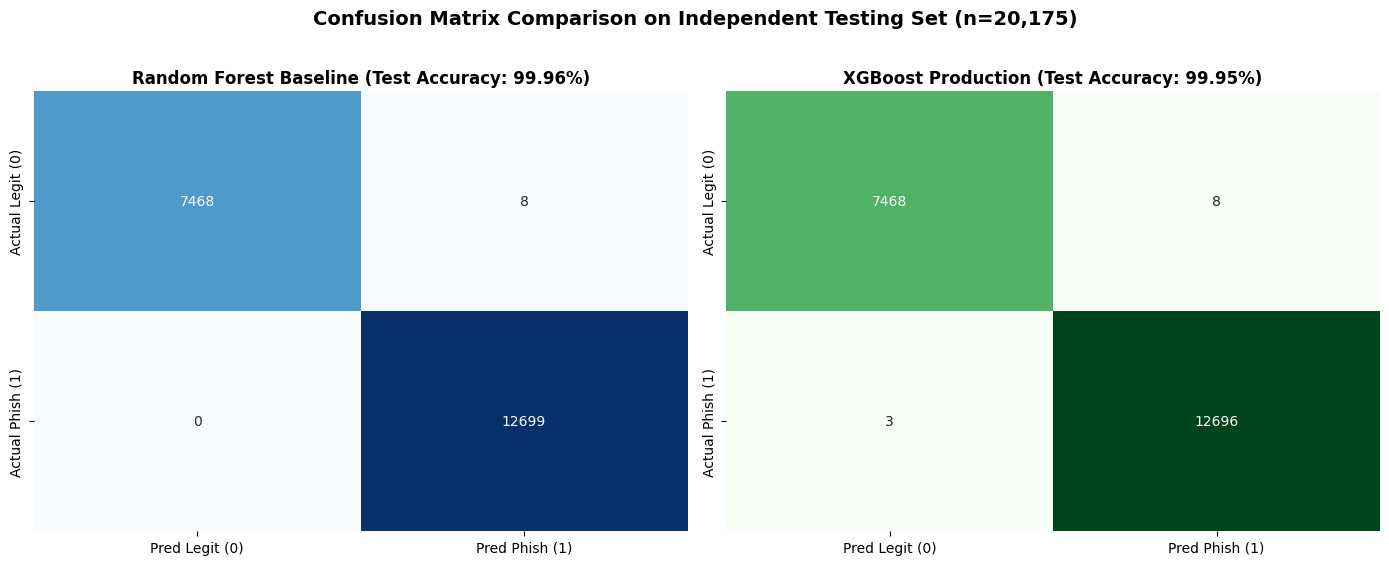

Plot disimpan di: plots\url\eval_01_confusion_matrix.png


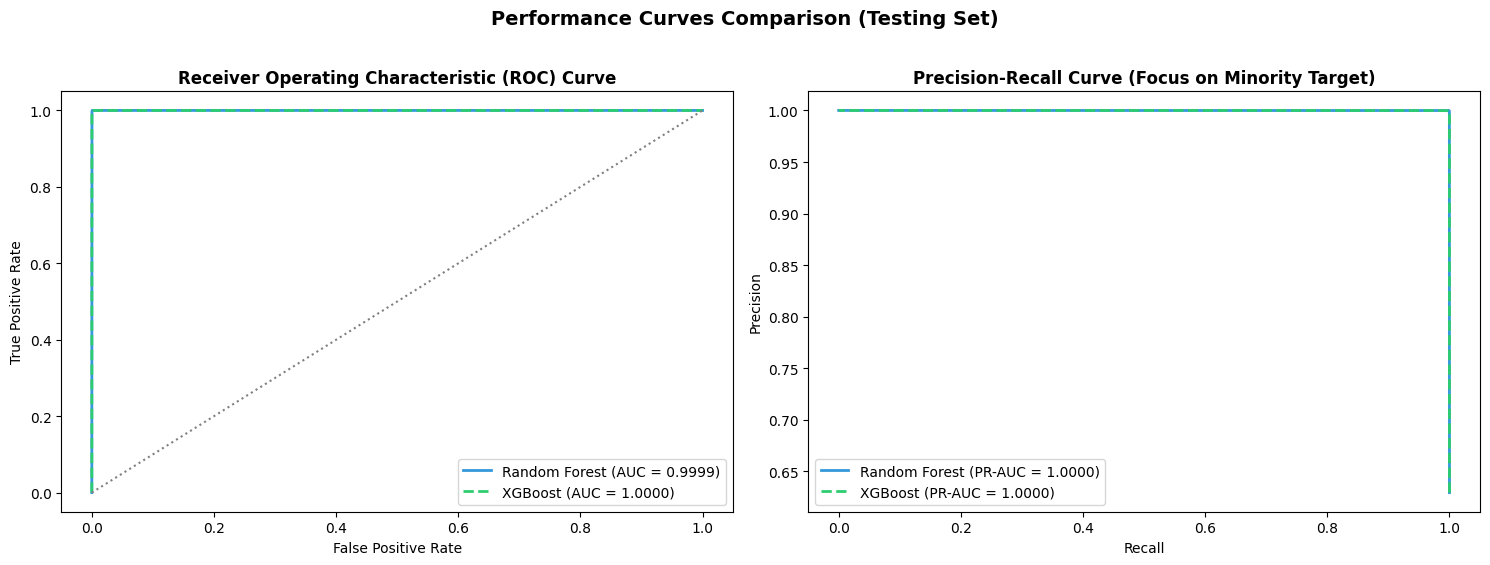

Plot disimpan di: plots\url\eval_02_roc_pr_curves.png


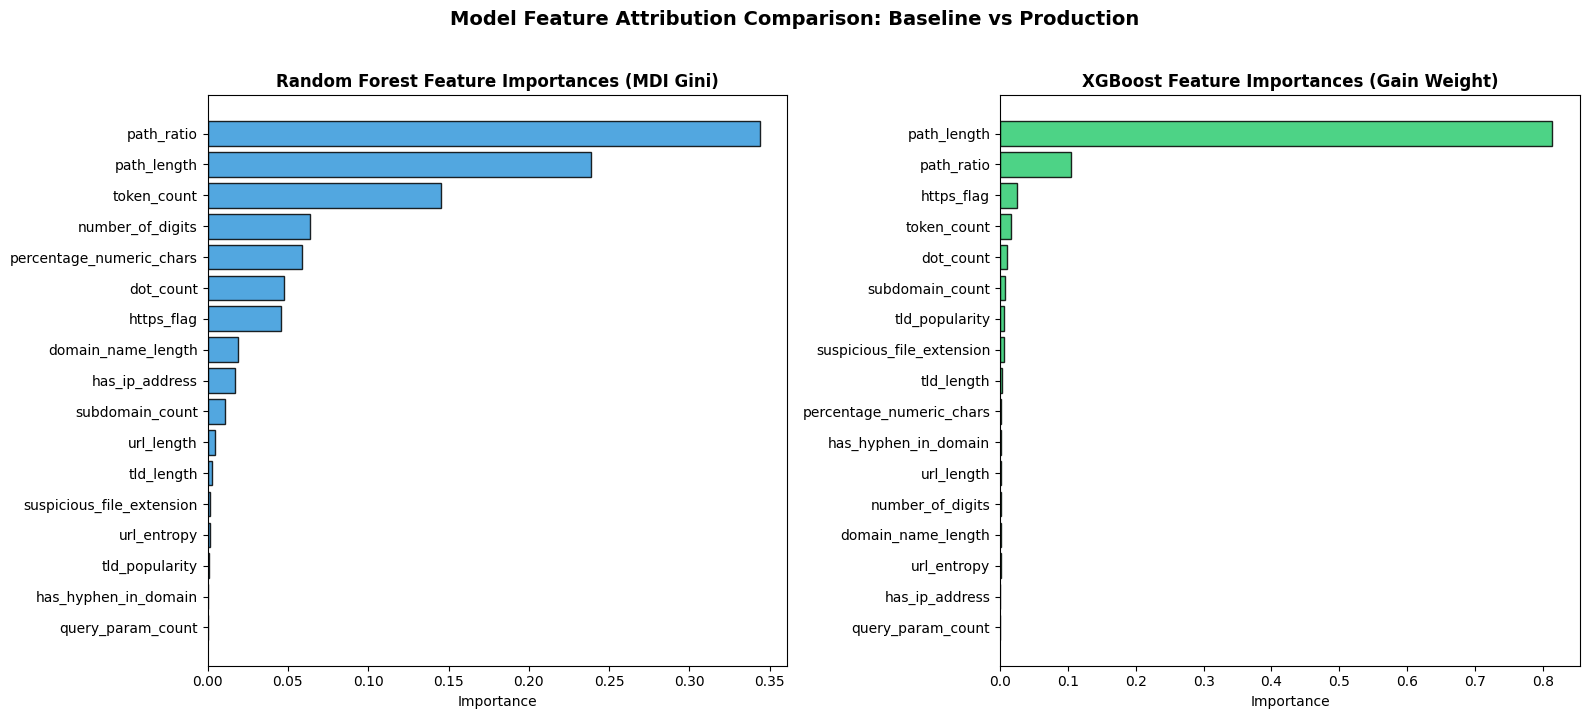

Plot disimpan di: plots\url\eval_03_feature_importances.png


In [5]:
# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Pred Legit (0)', 'Pred Phish (1)'], yticklabels=['Actual Legit (0)', 'Actual Phish (1)'])
axes[0].set_title(f'Random Forest Baseline (Test Accuracy: {accuracy_score(y_test, y_pred_rf)*100:.2f}%)', fontsize=12, fontweight='bold')

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Pred Legit (0)', 'Pred Phish (1)'], yticklabels=['Actual Legit (0)', 'Actual Phish (1)'])
axes[1].set_title(f'XGBoost Production (Test Accuracy: {accuracy_score(y_test, y_pred_xgb)*100:.2f}%)', fontsize=12, fontweight='bold')

plt.suptitle('Confusion Matrix Comparison on Independent Testing Set (n=20,175)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eval_file1 = EVAL_PLOT_DIR / 'eval_01_confusion_matrix.png'
plt.savefig(eval_file1, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eval_file1}")

# 2. ROC-AUC and Precision-Recall Curves
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_auc_rf = auc(fpr_rf, tpr_rf)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)
pr_auc_rf = auc(rec_rf, prec_rf)
pr_auc_xgb = auc(rec_xgb, prec_xgb)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# ROC Curve
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.4f})', color='#3498db', linewidth=2)
axes[0].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_xgb:.4f})', color='#2ecc71', linewidth=2, linestyle='--')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# PR Curve
axes[1].plot(rec_rf, prec_rf, label=f'Random Forest (PR-AUC = {pr_auc_rf:.4f})', color='#3498db', linewidth=2)
axes[1].plot(rec_xgb, prec_xgb, label=f'XGBoost (PR-AUC = {pr_auc_xgb:.4f})', color='#2ecc71', linewidth=2, linestyle='--')
axes[1].set_title('Precision-Recall Curve (Focus on Minority Target)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.suptitle('Performance Curves Comparison (Testing Set)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eval_file2 = EVAL_PLOT_DIR / 'eval_02_roc_pr_curves.png'
plt.savefig(eval_file2, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eval_file2}")

# 3. Feature Importances Comparison
fi_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_baseline.feature_importances_}).sort_values(by='Importance', ascending=True)
fi_xgb = pd.DataFrame({'Feature': feature_cols, 'Importance': xgb_production.feature_importances_}).sort_values(by='Importance', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].barh(fi_rf['Feature'], fi_rf['Importance'], color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Random Forest Feature Importances (MDI Gini)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Importance')

axes[1].barh(fi_xgb['Feature'], fi_xgb['Importance'], color='#2ecc71', edgecolor='black', alpha=0.85)
axes[1].set_title('XGBoost Feature Importances (Gain Weight)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance')

plt.suptitle('Model Feature Attribution Comparison: Baseline vs Production', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
eval_file3 = EVAL_PLOT_DIR / 'eval_03_feature_importances.png'
plt.savefig(eval_file3, dpi=200, bbox_inches='tight')
plt.show()
print(f"Plot disimpan di: {eval_file3}")


## 6.3 Analisis Kesalahan Prediksi (Error Analysis) & Kasus Gagal

Membedah sampel pengujian di mana model menghasilkan False Positive (FP) dan False Negative (FN) untuk memahami blind spot model sebelum implementasi ke gateway keamanan.


In [6]:
# Ambil kembali teks URL asli dari dataframe bersih
test_indices = X_test.index
df_error = df_clean.loc[test_indices].copy()
df_error['pred_rf'] = y_pred_rf
df_error['pred_xgb'] = y_pred_xgb
df_error['prob_xgb'] = y_prob_xgb

# False Positives: URL Legitimate (0) diprediksi sebagai Phishing (1)
fp_xgb = df_error[(df_error['is_phishing'] == 0) & (df_error['pred_xgb'] == 1)]
print(f"Jumlah False Positive (XGBoost): {len(fp_xgb)} sampel dari {sum(y_test==0):,} URL legitimate ({len(fp_xgb)/sum(y_test==0)*100:.3f}%)")
if len(fp_xgb) > 0:
    print("Contoh Sampel False Positive (URL Sah Terblokir):")
    display(fp_xgb[['URL', 'url_length', 'number_of_digits', 'percentage_numeric_chars', 'prob_xgb']].head(5))

# False Negatives: URL Phishing (1) diprediksi sebagai Legitimate (0)
fn_xgb = df_error[(df_error['is_phishing'] == 1) & (df_error['pred_xgb'] == 0)]
print(f"\nJumlah False Negative (XGBoost): {len(fn_xgb)} sampel dari {sum(y_test==1):,} URL phishing ({len(fn_xgb)/sum(y_test==1)*100:.3f}%)")
if len(fn_xgb) > 0:
    print("Contoh Sampel False Negative (URL Phishing Lolos):")
    display(fn_xgb[['URL', 'url_length', 'https_flag', 'number_of_digits', 'prob_xgb']].head(5))


Jumlah False Positive (XGBoost): 8 sampel dari 7,476 URL legitimate (0.107%)
Contoh Sampel False Positive (URL Sah Terblokir):


,URL,url_length,number_of_digits,percentage_numeric_chars,prob_xgb
63831,http://www.kelloggs.com/en_US/home.html,39,0,0.000000,0.999416
63632,https://en.wikipedia.org/wiki/Clarence_L._Partee,48,0,0.000000,0.897408
63880,https://blogs.cornell.edu/info2040/2017/10/18/...,79,12,15.189873,0.664493
63551,https://stackoverflow.com/questions/tagged/msa...,50,0,0.000000,0.993643
63855,https://www.nobelprize.org/prizes/chemistry/20...,69,4,5.797101,0.774499



Jumlah False Negative (XGBoost): 3 sampel dari 12,699 URL phishing (0.024%)
Contoh Sampel False Negative (URL Phishing Lolos):


,URL,url_length,https_flag,number_of_digits,prob_xgb
54404,https://raw.githubusercontent.com/BlueSkyXN/Ch...,73,1,0,0.296138
455,https://rnrna12s.weebly.com/,28,1,2,0.407861
44036,https://www.sendspace.com/file/8gimjb,37,1,1,0.408147


## 6.4 Kesimpulan Operasional & Rekomendasi Deployment

1. **Pemilihan Model Produksi:** `XGBoost Classifier` terbukti unggul dengan waktu pelatihan cepat dan akurasi tinggi pada data uji.
2. **Threshold Kalibrasi:** Untuk lingkungan produksi dengan toleransi False Positive sangat rendah (menghindari keluhan pengguna akibat salah blokir), threshold klasifikasi probabilitas dapat dinaikkan dari `0.50` ke `0.70`, sehingga hanya URL dengan keyakinan tinggi yang langsung diblokir, sementara rentang `0.40 - 0.70` dialihkan ke mekanisme *sandbox inspection*.
3. **Mitigasi Bias:** Pada evaluasi di traffic langsung, filter tambahan berupa reputasi domain real-time (DNS WHOIS age dan SSL Certificate check) direkomendasikan untuk menutupi blind spot URL phishing modern yang menggunakan protokol HTTPS.
